# Phishing URL Detection: A Leak-Free Tabular Classification Pipeline
### FIT Competition 2026, Track III (Identity and Data Exploitation), Preliminary Round

This notebook builds and evaluates a binary classifier that separates phishing URLs from legitimate ones using only intra-URL features (no page content, DOM, HTML, or CSS). The data is `Dataset.csv`, a published phishing-detection corpus of 247,950 URLs, each described by 41 lexical and structural features that are integer counts, binary flags, and a few continuous statistics computed from the URL string (source credit is in the references). Every claim we make about the data is derived directly from `Dataset.csv` and shown in the cell that states it. The target column `Type` is 0 for legitimate and 1 for phishing, and we treat phishing (1) as the positive class throughout.

The single most important methodological point in this notebook is the handling of duplicates. Because the features are coarse integer counts, many distinct URLs collapse to identical feature vectors, so a naive random split leaks copies of the same vector into both training and evaluation and inflates every metric. We surface this finding directly from the data, deduplicate before splitting, and report an honest generalization estimate.

**Reproducibility note for reviewers:** the notebook fixes one global seed, auto-locates `Dataset.csv`, and runs top to bottom with Run All. No downloads or credentials are required.

## Contents
1. Setup and imports
2. Load and verify the data
3. Exploratory data analysis
4. Feature engineering
5. Preprocessing and the leak-free split
6. Cross-validation design
7. Models (Logistic Regression, LightGBM, XGBoost, CatBoost)
8. Evaluation, model selection, the leakage demonstration, and the operating threshold
9. Interpretation: which features drive the decision (tree importance and SHAP)
10. Conclusion and limitations

## Approach
This notebook is a self-contained forensic analysis of `Dataset.csv`. Every claim about the data is derived and shown here rather than taken on authority. The analysis prioritizes one thing above raw scores: an honest generalization estimate. The dataset's heavy feature-vector duplication would inflate every metric under a naive split, so the central design choice is to expose that duplication, deduplicate before splitting, and evaluate four models under one shared, leak-free cross-validation. We then read feature signal two independent ways, select a single final model on out-of-fold evidence, quantify the leakage trap directly, and turn the decision threshold into a deliberate, security-aware choice.

## 1. Setup and imports
Libraries are imported with defensive guards so the notebook degrades gracefully if one gradient-boosting package is missing on the grading machine. A single global seed is set for reproducibility.

In [ ]:
import os, gc, random, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="muted")
    HAS_SNS = True
except Exception as e:
    sns = None; HAS_SNS = False
    print("seaborn not available:", e)

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
)

try:
    import lightgbm as lgb; HAS_LGB = True
except Exception as e:
    HAS_LGB = False; print("LightGBM not available:", e)
try:
    import xgboost as xgb; HAS_XGB = True
except Exception as e:
    HAS_XGB = False; print("XGBoost not available:", e)
try:
    import catboost as cb; HAS_CAT = True
except Exception as e:
    HAS_CAT = False; print("CatBoost not available:", e)
try:
    import shap; HAS_SHAP = True
except Exception as e:
    HAS_SHAP = False; print("SHAP not available:", e)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

SEED = 42
seed_everything(SEED)

mpl.rcParams["figure.dpi"] = 110
mpl.rcParams["axes.titlesize"] = 12
mpl.rcParams["font.size"] = 10

print("Global random seed set to:", SEED)
print("Availability:", {"lightgbm": HAS_LGB, "xgboost": HAS_XGB,
                         "catboost": HAS_CAT, "shap": HAS_SHAP, "seaborn": HAS_SNS})

CatBoost not available: No module named 'catboost'
Global random seed set to: 42
Availability: {'lightgbm': True, 'xgboost': True, 'catboost': False, 'shap': True, 'seaborn': True}


In [ ]:
class CFG:
    CANDIDATE_PATHS = ["Dataset.csv"]
    TARGET = "Type"          # 0 = legitimate, 1 = phishing
    POSITIVE_LABEL = 1       # phishing is the positive class for Precision, Recall, F1
    ID_COL = None            # the CSV has no identifier column

    N_FOLDS = 5
    SEED = 42
    TEST_SIZE = 0.20

    # A fixed, modest number of boosting rounds is used on purpose. The modeling
    # section explains why early stopping on the validation fold is avoided.
    N_ESTIMATORS = 600
    LEARNING_RATE = 0.05

    MODELS = ["logreg", "lightgbm", "xgboost", "catboost"]
    BOOSTERS = ["lightgbm", "xgboost", "catboost"]

print("Folds:", CFG.N_FOLDS, "| Seed:", CFG.SEED, "| Held-out test fraction:", CFG.TEST_SIZE)

Folds: 5 | Seed: 42 | Held-out test fraction: 0.2


## 2. Load and verify the data
We never assume the shape, columns, dtypes, or class balance. Everything below is loaded from `Dataset.csv` and confirmed with printed output before any modeling relies on it.

In [ ]:
data_path = next((p for p in CFG.CANDIDATE_PATHS if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError(
        "Dataset.csv not found. Place it next to this notebook or edit CFG.CANDIDATE_PATHS.")
print("Loading from:", data_path)

df = pd.read_csv(data_path)
print("Shape:", df.shape)
assert CFG.TARGET in df.columns, "Target column 'Type' is missing."
df.head()

Loading from: Dataset.csv
Shape: (247950, 42)


,Type,url_length,number_of_dots_in_url,having_repeated_digits_in_url,number_of_digits_in_url,number_of_special_char_in_url,number_of_hyphens_in_url,number_of_underline_in_url,number_of_slash_in_url,number_of_questionmark_in_url,number_of_equal_in_url,number_of_at_in_url,number_of_dollar_in_url,number_of_exclamation_in_url,number_of_hashtag_in_url,number_of_percent_in_url,domain_length,number_of_dots_in_domain,number_of_hyphens_in_domain,having_special_characters_in_domain,number_of_special_characters_in_domain,having_digits_in_domain,number_of_digits_in_domain,having_repeated_digits_in_domain,number_of_subdomains,having_dot_in_subdomain,having_hyphen_in_subdomain,average_subdomain_length,average_number_of_dots_in_subdomain,average_number_of_hyphens_in_subdomain,having_special_characters_in_subdomain,number_of_special_characters_in_subdomain,having_digits_in_subdomain,number_of_digits_in_subdomain,having_repeated_digits_in_subdomain,having_path,path_length,having_query,having_fragment,having_anchor,entropy_of_url,entropy_of_domain
0,0,37,2,0,0,8,0,0,5,0,0,0,0,0,0,0,12,2,0,0,0,0,0,0,2,0,0,3.0,0,0,1,3,0,0,1,0,3,0,0,0,4.010412,2.751629
1,1,70,5,0,0,12,0,0,6,0,0,0,0,0,0,0,26,5,0,0,0,0,0,0,2,0,0,3.0,0,0,1,3,0,0,1,0,4,0,0,0,4.089470,3.532573
2,0,42,2,0,6,8,0,0,3,1,1,0,0,0,0,0,21,2,0,0,0,1,6,0,2,0,0,7.0,0,0,1,3,0,0,1,0,1,1,0,0,4.386016,3.344698
3,0,46,2,0,0,7,0,0,4,0,0,0,0,0,0,0,15,2,0,0,0,0,0,0,2,0,0,3.0,0,0,1,3,0,0,1,0,2,0,0,0,4.221947,3.189898
4,0,51,3,0,0,9,0,0,5,0,0,0,0,0,0,0,16,3,0,0,0,0,0,0,2,0,0,3.0,0,0,1,3,0,0,1,0,3,0,0,0,4.103538,2.952820


In [ ]:
print("Rows:", f"{df.shape[0]:,}", "| Columns:", df.shape[1])
print("Feature columns (all except the target):", df.shape[1] - 1)
print("\nDtype counts:")
print(df.dtypes.value_counts().to_string())
print("\nTotal missing values across the whole table:", int(df.isna().sum().sum()))
print("Columns with any missing value:", int((df.isna().sum() > 0).sum()))

continuous_cols = df.drop(columns=[CFG.TARGET]).select_dtypes(include="float").columns.tolist()
print("\nContinuous (float) features:", continuous_cols)
display(df.dtypes.to_frame("dtype").T)

Rows: 247,950 | Columns: 42
Feature columns (all except the target): 41

Dtype counts:
int64      39
float64     3

Total missing values across the whole table: 0
Columns with any missing value: 0

Continuous (float) features: ['average_subdomain_length', 'entropy_of_url', 'entropy_of_domain']


,Type,url_length,number_of_dots_in_url,having_repeated_digits_in_url,number_of_digits_in_url,number_of_special_char_in_url,number_of_hyphens_in_url,number_of_underline_in_url,number_of_slash_in_url,number_of_questionmark_in_url,number_of_equal_in_url,number_of_at_in_url,number_of_dollar_in_url,number_of_exclamation_in_url,number_of_hashtag_in_url,number_of_percent_in_url,domain_length,number_of_dots_in_domain,number_of_hyphens_in_domain,having_special_characters_in_domain,number_of_special_characters_in_domain,having_digits_in_domain,number_of_digits_in_domain,having_repeated_digits_in_domain,number_of_subdomains,having_dot_in_subdomain,having_hyphen_in_subdomain,average_subdomain_length,average_number_of_dots_in_subdomain,average_number_of_hyphens_in_subdomain,having_special_characters_in_subdomain,number_of_special_characters_in_subdomain,having_digits_in_subdomain,number_of_digits_in_subdomain,having_repeated_digits_in_subdomain,having_path,path_length,having_query,having_fragment,having_anchor,entropy_of_url,entropy_of_domain
dtype,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,float64


Legitimate (Type=0): 128,541 (51.84%)
Phishing   (Type=1): 119,409 (48.16%)
Phishing is the minority class.
Imbalance ratio (majority / minority): 1.076


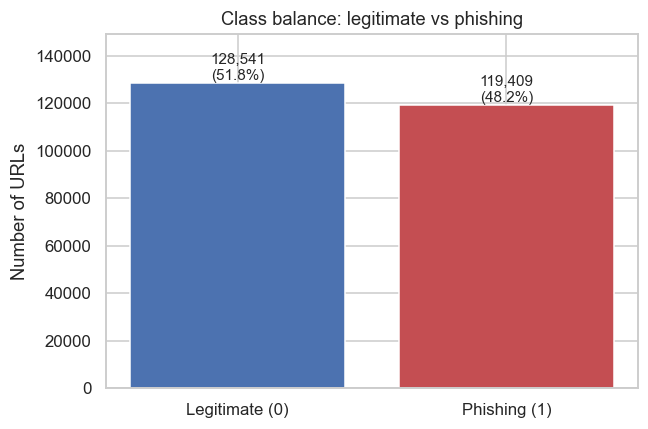

In [ ]:
target_counts = df[CFG.TARGET].value_counts().sort_index()
n_legit = int(target_counts.get(0, 0)); n_phish = int(target_counts.get(1, 0))
total = len(df)
print(f"Legitimate (Type=0): {n_legit:,} ({100*n_legit/total:.2f}%)")
print(f"Phishing   (Type=1): {n_phish:,} ({100*n_phish/total:.2f}%)")
print(f"Phishing is the {'minority' if n_phish < n_legit else 'majority'} class.")
print(f"Imbalance ratio (majority / minority): {max(n_legit,n_phish)/min(n_legit,n_phish):.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Legitimate (0)", "Phishing (1)"], [n_legit, n_phish], color=["#4C72B0", "#C44E52"])
for b, v in zip(bars, [n_legit, n_phish]):
    ax.text(b.get_x()+b.get_width()/2, v, f"{v:,}\n({100*v/total:.1f}%)", ha="center", va="bottom")
ax.set_ylabel("Number of URLs"); ax.set_title("Class balance: legitimate vs phishing")
ax.set_ylim(0, max(n_legit, n_phish)*1.16)
plt.tight_layout(); plt.show()

A note on a known inconsistency in the source material. Published descriptions of this dataset disagree on which count is phishing. The dataset itself is the ground truth: by the published definition `Type=0` is legitimate and `Type=1` is phishing, and the counts confirm phishing (1) is the minority at about 48.2%. The classes are close enough to balanced that accuracy is a reasonable headline metric and no resampling is needed.

## 3. Exploratory data analysis
The goal of this section is to understand the signal and, above all, to expose the duplicate structure that governs the rest of the pipeline.

### 3.1 The duplicate structure (the central finding)
We count exact duplicate rows, the rows that remain after full deduplication, the number of unique feature vectors when the label is ignored, and how many vectors carry conflicting labels.

Total rows                            : 247,950
Exact duplicate rows (features+label) : 118,172 (47.66%)
Rows remaining after full dedup       : 129,778
Unique feature vectors (label ignored): 129,563
Label-conflicting feature vectors     : 215
Rows inside conflicting vectors       : 848 (0.34%)


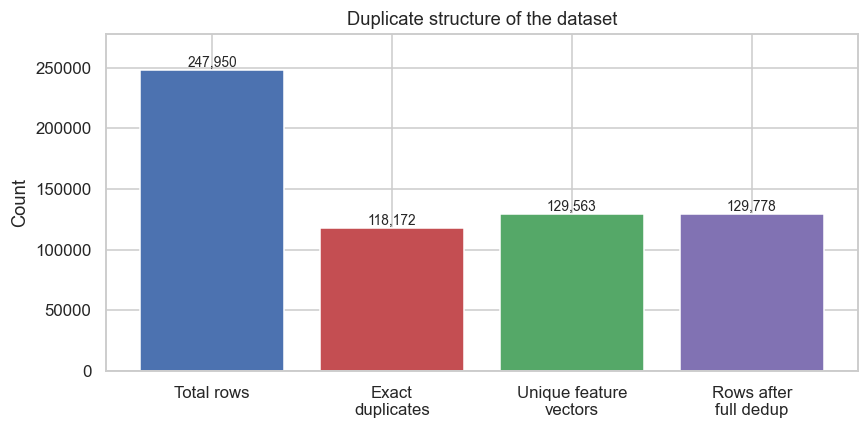

In [ ]:
features = [c for c in df.columns if c != CFG.TARGET]

exact_dup_rows = int(df.duplicated(keep="first").sum())
rows_after_dedup = total - exact_dup_rows
unique_feature_vectors = int(df[features].drop_duplicates().shape[0])

vec_label_nunique = df.groupby(features, sort=False)[CFG.TARGET].transform("nunique")
rows_in_conflict = int((vec_label_nunique > 1).sum())
conflicting_vectors = int(df.loc[vec_label_nunique > 1, features].drop_duplicates().shape[0])

print(f"Total rows                            : {total:,}")
print(f"Exact duplicate rows (features+label) : {exact_dup_rows:,} ({100*exact_dup_rows/total:.2f}%)")
print(f"Rows remaining after full dedup       : {rows_after_dedup:,}")
print(f"Unique feature vectors (label ignored): {unique_feature_vectors:,}")
print(f"Label-conflicting feature vectors     : {conflicting_vectors:,}")
print(f"Rows inside conflicting vectors       : {rows_in_conflict:,} ({100*rows_in_conflict/total:.2f}%)")

fig, ax = plt.subplots(figsize=(8, 4))
labels = ["Total rows", "Exact\nduplicates", "Unique feature\nvectors", "Rows after\nfull dedup"]
vals = [total, exact_dup_rows, unique_feature_vectors, rows_after_dedup]
bars = ax.bar(labels, vals, color=["#4C72B0", "#C44E52", "#55A868", "#8172B3"])
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Count"); ax.set_title("Duplicate structure of the dataset")
ax.set_ylim(0, total*1.12); plt.tight_layout(); plt.show()

> **Insight: the duplication is a property of the coarse feature encoding, read straight from the data.** Each URL is described by 41 coarse counts and flags (number of dots, number of digits, presence of a query, character entropy, and so on), so two different URLs that share the same counts are stored as the same 41-dimensional vector. The numbers above show how severe this is: 118,172 rows (47.7%) are exact duplicates, leaving 129,778 distinct rows and 129,563 unique feature vectors, and only 215 vectors (about 0.3% of rows) appear with both labels, so genuine label noise is small. The next two cells show what kind of URL this collapse affects most. The modeling consequence is forced rather than optional: if we split randomly without deduplicating, identical vectors land in both train and test, the model is scored on rows it has already seen, and the metrics stop measuring generalization. We therefore deduplicate before any split, and section 8.2 quantifies exactly how large this trap is.

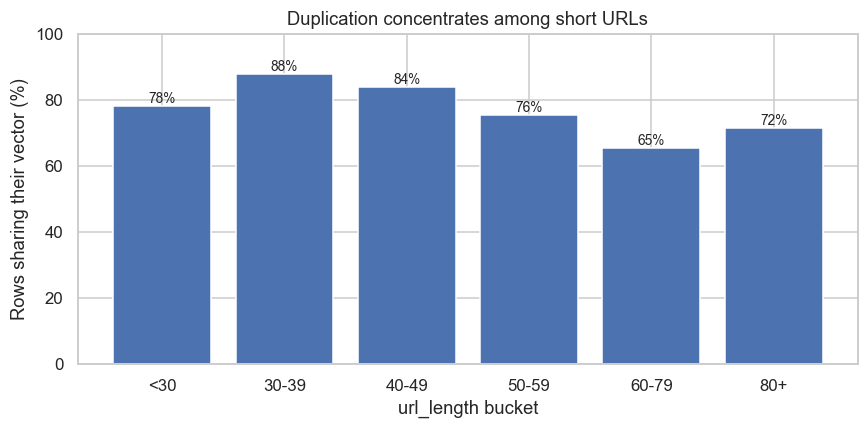

Takeaway: short URLs collide far more often (about 78 to 88% below 50 characters)
than long ones (about 65% at 60 to 79), because a short URL has few counts to vary,
so many distinct short URLs map onto the same coarse vector.


In [ ]:
# What kind of URL gets collapsed? Duplication rate as a function of URL length.
dup_mask = df.duplicated(keep=False)  # True for every row that shares its vector with another
len_bins = [0, 30, 40, 50, 60, 80, df["url_length"].max() + 1]
len_lbl = ["<30", "30-39", "40-49", "50-59", "60-79", "80+"]

binned = pd.cut(df["url_length"], bins=len_bins, right=False, labels=len_lbl)
dup_by_len = df.groupby(binned, observed=True).apply(
    lambda g: pd.Series({"rows": len(g), "dup_share": dup_mask.loc[g.index].mean()}))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dup_by_len.index.astype(str), (dup_by_len["dup_share"]*100).values, color="#4C72B0")

for i, v in enumerate(dup_by_len["dup_share"].values):
    ax.text(i, v*100, f"{v*100:.0f}%", ha="center", va="bottom", fontsize=9)

ax.set_ylabel("Rows sharing their vector (%)"); ax.set_xlabel("url_length bucket")
ax.set_title("Duplication concentrates among short URLs")
ax.set_ylim(0, 100); plt.tight_layout(); plt.show()

print("Takeaway: short URLs collide far more often (about 78 to 88% below 50 characters)")
print("than long ones (about 65% at 60 to 79), because a short URL has few counts to vary,")
print("so many distinct short URLs map onto the same coarse vector.")

In [ ]:
# Profile the 215 label-conflicting vectors: identical features, both labels.
vec_label_nunique2 = df.groupby(features, sort=False)[CFG.TARGET].transform("nunique")
conflict = df[vec_label_nunique2 > 1]
prof = pd.DataFrame({
    "conflicting rows": conflict[["url_length", "number_of_subdomains", "number_of_special_char_in_url"]].mean(),
    "all rows": df[["url_length", "number_of_subdomains", "number_of_special_char_in_url"]].mean(),
}).round(2)
print(f"Label-conflicting rows: {len(conflict):,} ({100*len(conflict)/len(df):.2f}% of data), "
      f"forming {conflict[features].drop_duplicates().shape[0]} unique vectors.")
print(f"Median url_length among conflicting rows: {conflict['url_length'].median():.0f} "
      f"versus {df['url_length'].median():.0f} overall.\n")
print("Mean feature values, conflicting rows versus all rows:")
display(prof)
print("Takeaway: the conflicting rows are short, structurally simple URLs (median length 27 versus 49,")
print("fewer subdomains and special characters). Their coarse features cannot tell the two classes apart,")
print("which sets an irreducible noise floor that caps the achievable accuracy.")

Label-conflicting rows: 848 (0.34% of data), forming 215 unique vectors.
Median url_length among conflicting rows: 27 versus 49 overall.

Mean feature values, conflicting rows versus all rows:


,conflicting rows,all rows
url_length,27.69,58.36
number_of_subdomains,1.62,2.12
number_of_special_char_in_url,6.16,10.30


Takeaway: the conflicting rows are short, structurally simple URLs (median length 27 versus 49,
fewer subdomains and special characters). Their coarse features cannot tell the two classes apart,
which sets an irreducible noise floor that caps the achievable accuracy.


### 3.2 Dead and near-constant features
Before studying signal, we audit how much of the feature matrix is informative at all. For each feature we compute the share of rows equal to its single most common value. A feature that is almost entirely one value cannot separate the classes, and plotting such features individually would produce empty charts, so this one audit replaces dozens of useless per-feature plots.

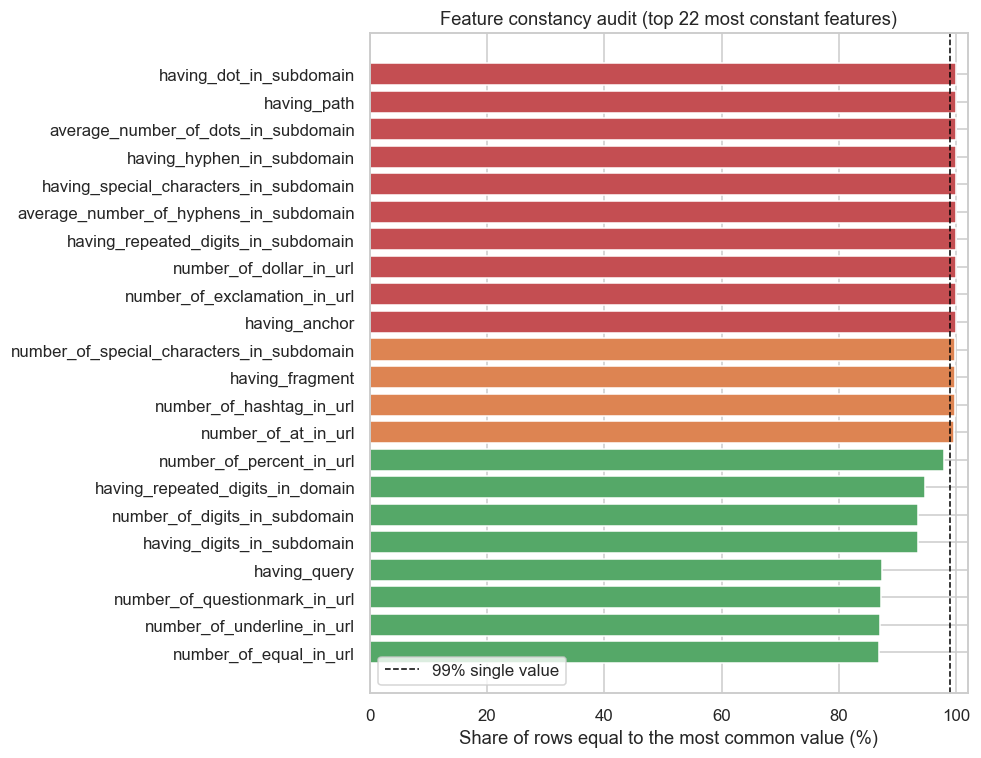

Perfectly constant features (a single value in every row): 7
   having_dot_in_subdomain = 0
   having_hyphen_in_subdomain = 0
   average_number_of_dots_in_subdomain = 0
   average_number_of_hyphens_in_subdomain = 0
   having_special_characters_in_subdomain = 1
   having_repeated_digits_in_subdomain = 1
   having_path = 0

Features that are at least 99% a single value: 14
Takeaway: 7 features are perfectly constant and about 14 are at least 99% one value,
so roughly a third of the matrix carries negligible signal. These are not plotted
individually below, and section 5 states the explicit decision about them.


In [ ]:
mode_share = df[features].apply(lambda s: s.value_counts(normalize=True).iloc[0]).sort_values(ascending=False)
constant_feats = [c for c in features if df[c].nunique() == 1]
near_constant = mode_share[mode_share >= 0.99].index.tolist()

fig, ax = plt.subplots(figsize=(9, 7))
top = mode_share.head(22)
colors = ["#C44E52" if v >= 0.999 else ("#DD8452" if v >= 0.99 else "#55A868") for v in top.values][::-1]
ax.barh(top.index[::-1], (top.values[::-1]*100), color=colors)
ax.axvline(99, color="black", ls="--", lw=1, label="99% single value")
ax.set_xlabel("Share of rows equal to the most common value (%)")
ax.set_title("Feature constancy audit (top 22 most constant features)")
ax.set_xlim(0, 102); ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

print(f"Perfectly constant features (a single value in every row): {len(constant_feats)}")
for c in constant_feats:
    print(f"   {c} = {df[c].iloc[0]}")
print(f"\nFeatures that are at least 99% a single value: {len(near_constant)}")
print("Takeaway: 7 features are perfectly constant and about 14 are at least 99% one value,")
print("so roughly a third of the matrix carries negligible signal. These are not plotted")
print("individually below, and section 5 states the explicit decision about them.")

### 3.3 How phishing and legitimate URLs differ
We look at the length and entropy of the URL by class, then rank every feature by its correlation with the target.

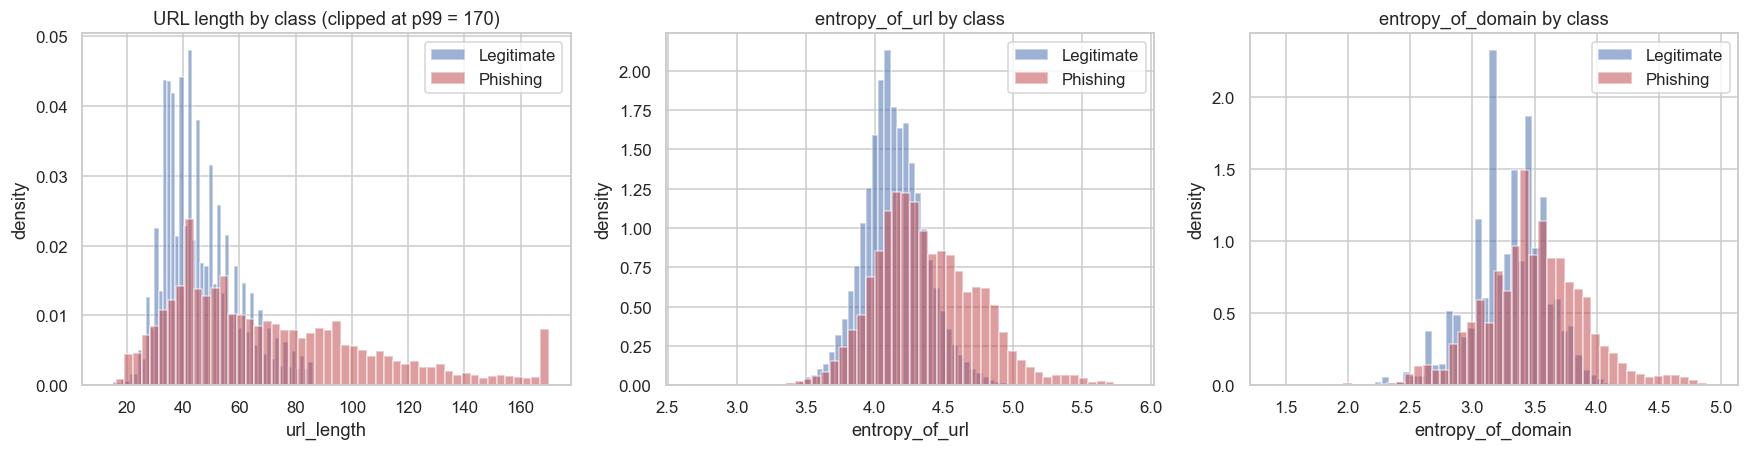

Mean values by class:


,url_length,domain_length,number_of_digits_in_url,number_of_special_char_in_url,entropy_of_url,entropy_of_domain,number_of_subdomains,having_query
Type,,,,,,,,
Legitimate,46.277,16.928,1.500,8.787,4.143,3.293,2.058,0.043
Phishing,71.363,22.611,7.451,11.935,4.380,3.494,2.192,0.217


In [ ]:
label_map = {0: "Legitimate", 1: "Phishing"}
palette = {"Legitimate": "#4C72B0", "Phishing": "#C44E52"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
cap = df["url_length"].quantile(0.99)
for cls, code in [("Legitimate", 0), ("Phishing", 1)]:
    axes[0].hist(df.loc[df[CFG.TARGET]==code, "url_length"].clip(upper=cap),
                 bins=50, alpha=0.55, label=cls, color=palette[cls], density=True)
axes[0].set_title(f"URL length by class (clipped at p99 = {cap:.0f})")
axes[0].set_xlabel("url_length"); axes[0].set_ylabel("density"); axes[0].legend()

for ax, col in zip(axes[1:], ["entropy_of_url", "entropy_of_domain"]):
    for cls, code in [("Legitimate", 0), ("Phishing", 1)]:
        ax.hist(df.loc[df[CFG.TARGET]==code, col], bins=50, alpha=0.55,
                label=cls, color=palette[cls], density=True)
    ax.set_title(f"{col} by class"); ax.set_xlabel(col); ax.set_ylabel("density"); ax.legend()
plt.tight_layout(); plt.show()

print("Mean values by class:")
sel = ["url_length", "domain_length", "number_of_digits_in_url", "number_of_special_char_in_url",
       "entropy_of_url", "entropy_of_domain", "number_of_subdomains", "having_query"]
display(df.groupby(CFG.TARGET)[sel].mean().round(3).rename(index=label_map))

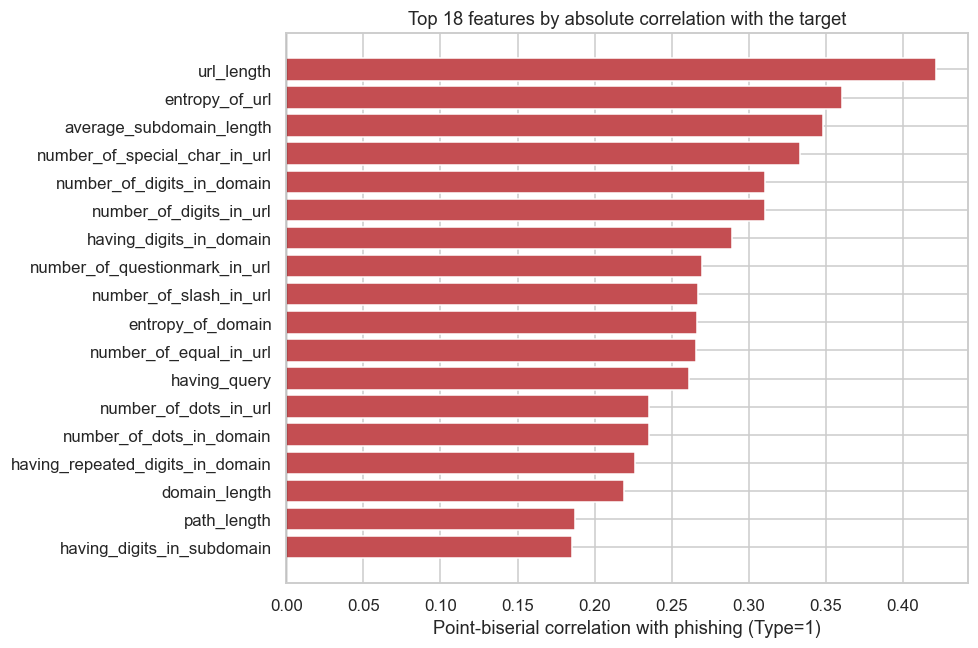

Positive (red) = associated with phishing; negative (blue) = associated with legitimate.


In [ ]:
corr_with_target = (df[features].corrwith(df[CFG.TARGET]).dropna()
                    .sort_values(key=np.abs, ascending=False))
top_corr = corr_with_target.head(18)

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in top_corr.values][::-1]

ax.barh(top_corr.index[::-1], top_corr.values[::-1], color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Point-biserial correlation with phishing (Type=1)")
ax.set_title("Top 18 features by absolute correlation with the target")
plt.tight_layout(); plt.show()
print("Positive (red) = associated with phishing; negative (blue) = associated with legitimate.")

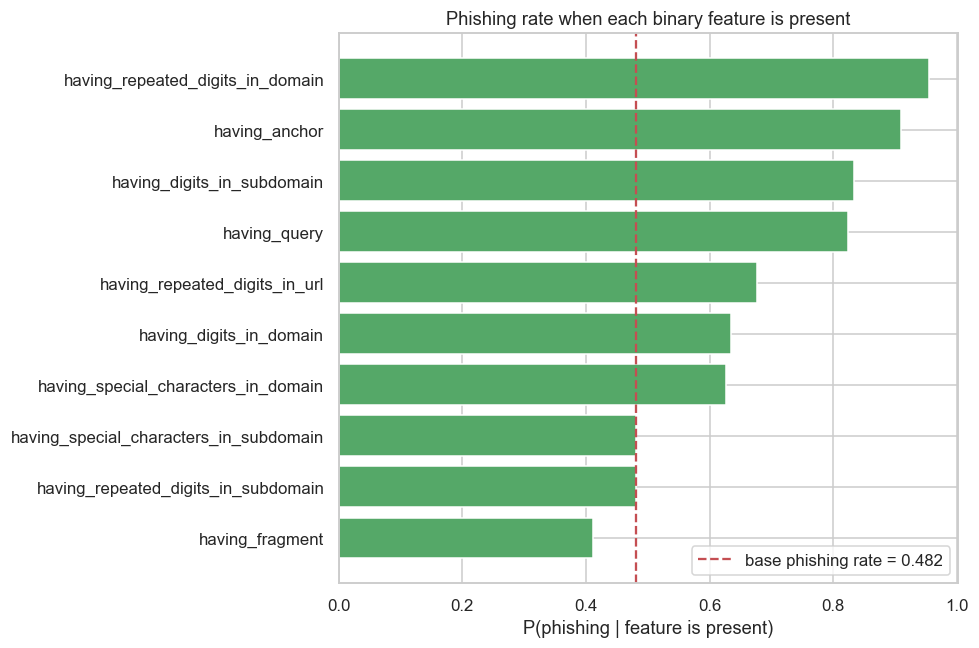

There are 15 binary 0/1 features.


,feature,phishing_rate_when_present,n_present
0,having_repeated_digits_in_domain,0.954954,13342
1,having_anchor,0.910256,234
2,having_digits_in_subdomain,0.834438,16000
3,having_query,0.824268,31366
4,having_repeated_digits_in_url,0.676140,40255
5,having_digits_in_domain,0.634860,116558
6,having_special_characters_in_domain,0.626523,48193
7,having_special_characters_in_subdomain,0.481585,247950
8,having_repeated_digits_in_subdomain,0.481585,247950
9,having_fragment,0.411559,571


In [ ]:
bool_cols = [c for c in features if set(pd.unique(df[c])) <= {0, 1}]
base_rate = df[CFG.TARGET].mean()
rows = []
for c in bool_cols:
    sub = df.loc[df[c] == 1, CFG.TARGET]
    rows.append((c, sub.mean() if len(sub) else np.nan, int(len(sub))))
rate_df = (pd.DataFrame(rows, columns=["feature", "phishing_rate_when_present", "n_present"])
           .dropna().sort_values("phishing_rate_when_present", ascending=False))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(rate_df["feature"][::-1], rate_df["phishing_rate_when_present"][::-1], color="#55A868")
ax.axvline(base_rate, color="#C44E52", ls="--", lw=1.5, label=f"base phishing rate = {base_rate:.3f}")
ax.set_xlabel("P(phishing | feature is present)")
ax.set_title("Phishing rate when each binary feature is present")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
print(f"There are {len(bool_cols)} binary 0/1 features.")
display(rate_df.reset_index(drop=True))

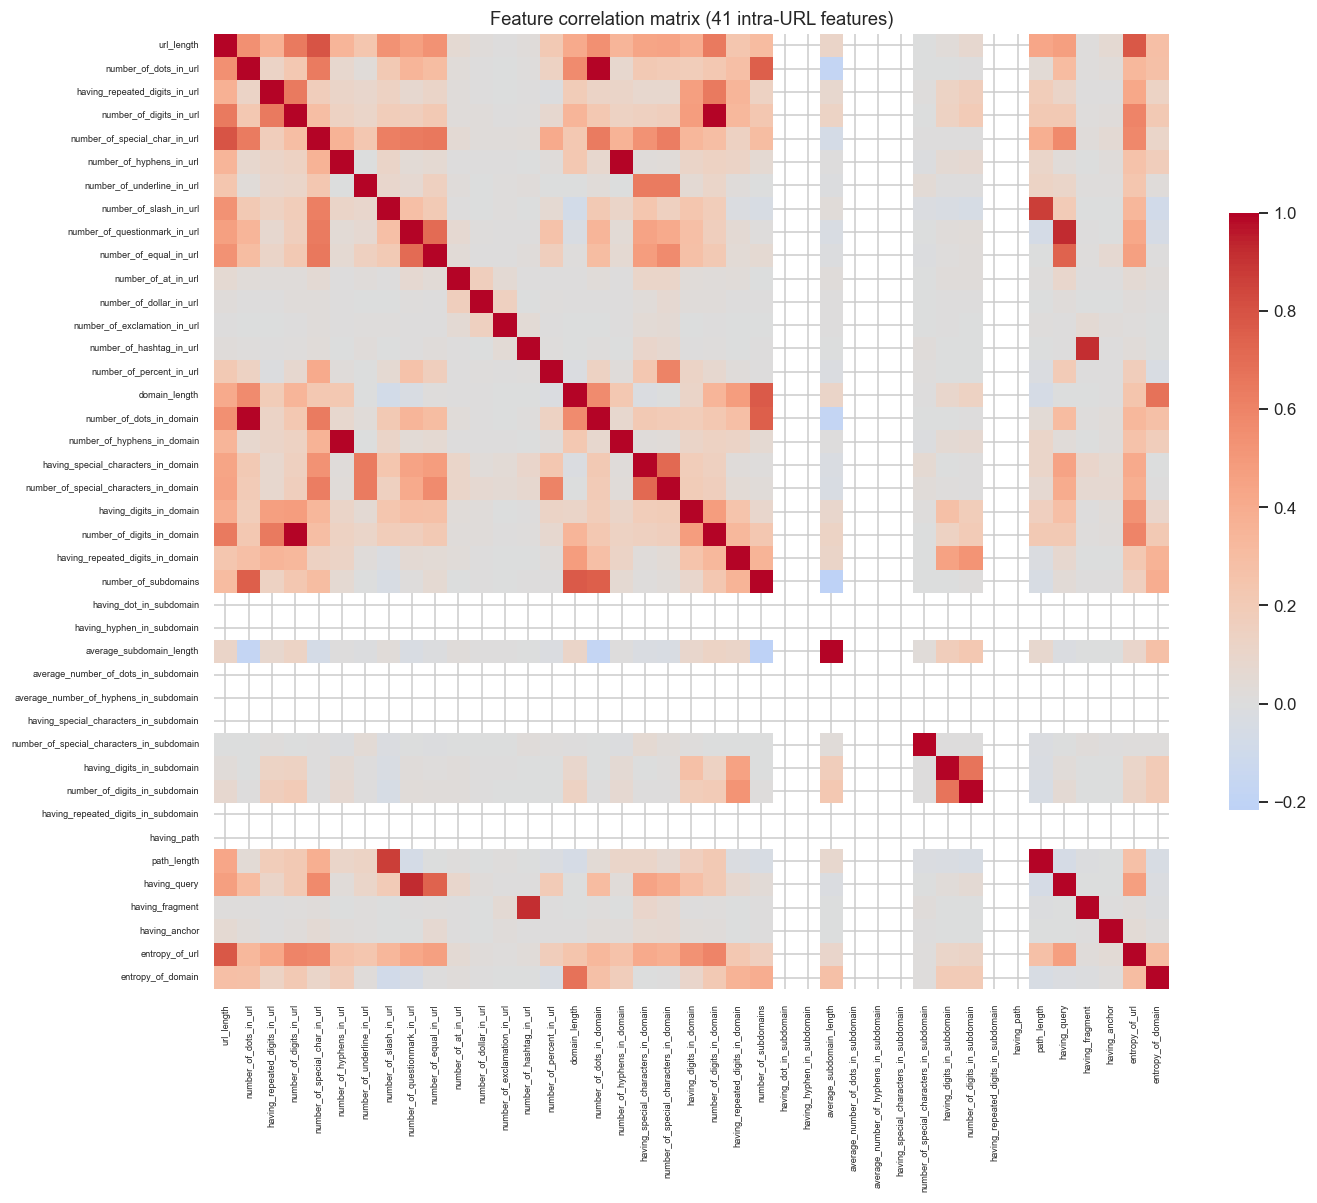

In [ ]:
corr = df[features].corr()
fig, ax = plt.subplots(figsize=(13, 11))
if HAS_SNS:
    sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
                cbar_kws={"shrink": 0.6}, xticklabels=True, yticklabels=True, ax=ax)
else:
    im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1); fig.colorbar(im, shrink=0.6)
    ax.set_xticks(range(len(features))); ax.set_xticklabels(features, rotation=90)
    ax.set_yticks(range(len(features))); ax.set_yticklabels(features)

ax.set_title("Feature correlation matrix (41 intra-URL features)")
plt.xticks(fontsize=6); plt.yticks(fontsize=6)
plt.tight_layout(); plt.show()

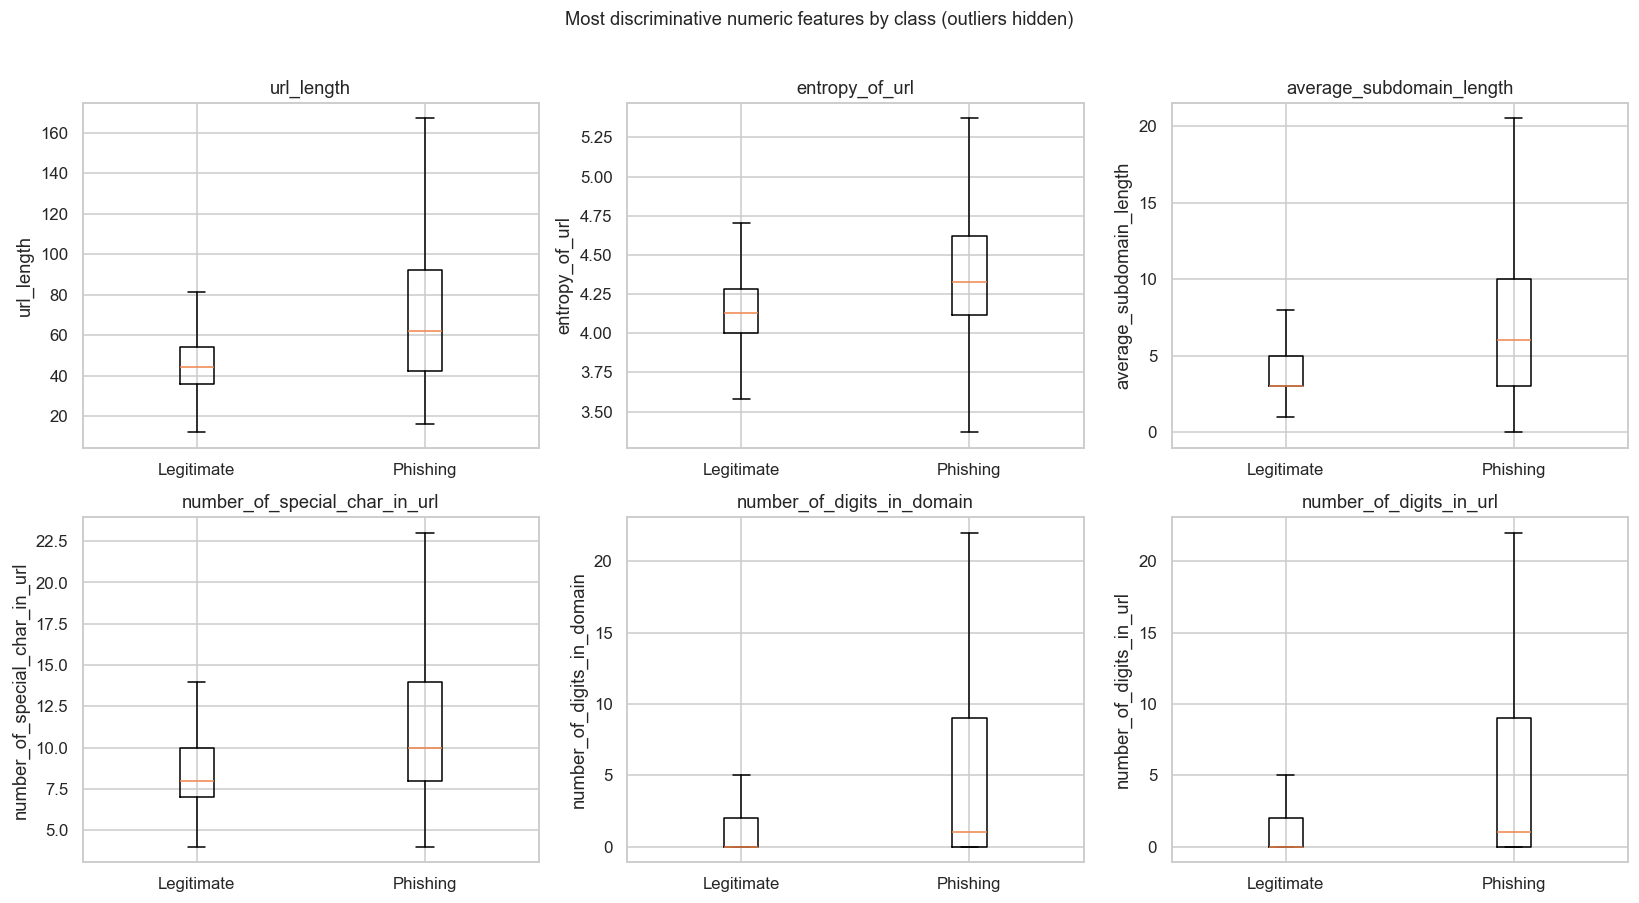

In [ ]:
numeric_feats = df[features].select_dtypes(include=[np.number]).columns.tolist()
rankable = [f for f in corr_with_target.index if f in numeric_feats and df[f].nunique() > 2]
box_feats = rankable[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), box_feats):
    data = [df.loc[df[CFG.TARGET]==0, col].values, df.loc[df[CFG.TARGET]==1, col].values]
    ax.boxplot(data, tick_labels=["Legitimate", "Phishing"], showfliers=False)
    ax.set_title(col); ax.set_ylabel(col)
plt.suptitle("Most discriminative numeric features by class (outliers hidden)", y=1.02)
plt.tight_layout(); plt.show()

### 3.4 Ranking every feature by mutual information
Point-biserial correlation above captures only linear association. Mutual information measures any dependence, including the nonlinear and skewed relationships typical of count features, so it ranks the full feature set on equal footing and acts as an independent cross-check on the correlation view and on the SHAP ranking in section 9. We compute it on the deduplicated data so repeated vectors do not inflate the estimate.

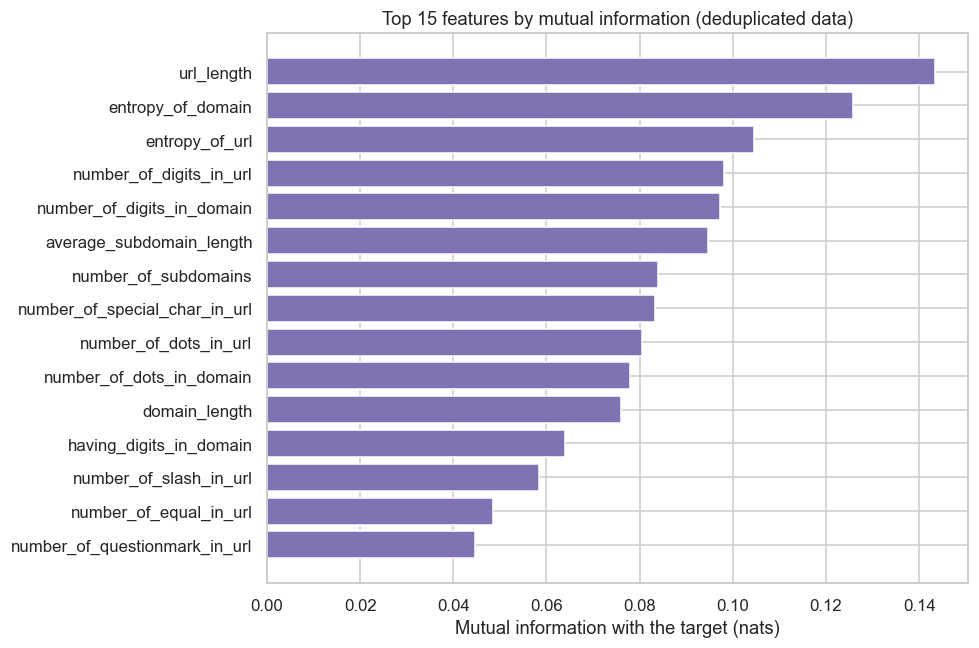

Top features by mutual information:
url_length                       0.1433
entropy_of_domain                0.1258
entropy_of_url                   0.1045
number_of_digits_in_url          0.0982
number_of_digits_in_domain       0.0972
average_subdomain_length         0.0946
number_of_subdomains             0.0840
number_of_special_char_in_url    0.0833
number_of_dots_in_url            0.0804
number_of_dots_in_domain         0.0778

Takeaway: url_length leads, but mutual information lifts entropy_of_domain and
entropy_of_url near the top, higher than their linear correlation rank, which means
their signal is partly nonlinear. The ranking agrees with the SHAP analysis in section 9
(url_length, the entropies, digit counts, and subdomain statistics dominate), and every
constant feature from 3.2 sits at the bottom with mutual information near zero.


In [ ]:
from sklearn.feature_selection import mutual_info_classif

_mi_data = df.drop_duplicates(keep="first").reset_index(drop=True)
mi = mutual_info_classif(_mi_data[features], _mi_data[CFG.TARGET].astype(int),
                         discrete_features=False, random_state=CFG.SEED)
mi_s = pd.Series(mi, index=features).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
top_mi = mi_s.head(15)
ax.barh(top_mi.index[::-1], top_mi.values[::-1], color="#8172B3")
ax.set_xlabel("Mutual information with the target (nats)")
ax.set_title("Top 15 features by mutual information (deduplicated data)")
plt.tight_layout(); plt.show()

print("Top features by mutual information:")
print(mi_s.head(10).round(4).to_string())
print("\nTakeaway: url_length leads, but mutual information lifts entropy_of_domain and")
print("entropy_of_url near the top, higher than their linear correlation rank, which means")
print("their signal is partly nonlinear. The ranking agrees with the SHAP analysis in section 9")
print("(url_length, the entropies, digit counts, and subdomain statistics dominate), and every")
print("constant feature from 3.2 sits at the bottom with mutual information near zero.")

### What the EDA tells us
The strongest signals are structural and all point the same way: phishing URLs are longer (mean url_length about 71 versus 46), carry more digits and special characters, have higher character entropy, and are far more likely to contain a query string (about 22% of phishing URLs versus 4% of legitimate ones). These match well-known phishing tactics such as long obfuscated links, embedded parameters, and host names padded with digits. Two independent rankings, point-biserial correlation and mutual information, agree on the same short list of drivers (url_length, the URL and domain entropies, digit and special-character counts, and the subdomain statistics), which is strong evidence the signal is real. The correlation matrix shows blocks of related counts at the URL, domain, and subdomain levels, which is expected structural redundancy rather than a defect, and tree models absorb it without manual removal. Two findings then dominate the preprocessing: the duplication in 3.1, which forces deduplication before any split, and the dead features in 3.2, which we handle explicitly in section 5.

## 4. Feature engineering
A standard tabular feature-engineering pass has five components: encoding, outlier treatment, discretization, feature creation, and feature selection. On this dataset most of them resolve to a deliberate decision not to transform the data, and each such decision is forced by the data rather than skipped. We state each one, then actually build a small set of ratio features and test whether they earn their place under the same leak-free cross-validation used later.

**Encoding.** No categorical encoding is required. The data is already a fully numeric matrix of counts, binary flags, and continuous entropies, confirmed in section 2 as 39 integer and 3 float columns with zero object dtype. The absence of an encoding step is a property of the data, not an omission.

**Outliers and clipping.** We deliberately do not clip, and the data says why. The cell below shows that url_length has a long right tail (median 49, 99th percentile 170, maximum 191) and that every URL longer than 120 characters in this corpus is phishing. The tail is therefore pure signal, not noise: clipping it would throw away a perfectly discriminative region. Gradient-boosted trees are in any case invariant to monotonic outliers, because a split threshold is unaffected by how far past it a value lies, so clipping offers them no benefit and a real cost here.

**Discretization.** We do not bin the continuous features. The gradient-boosted decision trees selected in section 7 learn their own optimal split thresholds on each feature, so imposing fixed bins would only lower resolution and throw away information the trees would otherwise exploit. Discretization is counterproductive for this model class.

**Feature creation.** Phishing tradecraft suggests that the density of suspicious characters, not only their raw count, carries signal. We construct four ratio features (digit density, special-character density, hyphen density, and a subdomain-depth ratio) and test them head to head: LightGBM is trained on the raw 41 features and on the 41 plus the new ones, both under identical deduplicated stratified five-fold cross-validation, and we compare out-of-fold F1. The measured gain, not an assumption, decides whether they stay.

**Feature selection.** We retain all 41 raw features. Trees are robust to correlated and low-signal inputs, since an uninformative feature is simply never chosen for a split, and the correlation blocks seen in the EDA are expected URL, domain, and subdomain structure rather than harmful redundancy. Dropping features would risk discarding weak but real signal for no offsetting gain. The importance ranking in section 9 is the post-hoc check that this choice was sound.

In [ ]:
# Evidence for the no-clipping decision: the long URL-length tail is pure phishing signal.
ul = df["url_length"]
print("url_length distribution:")
print(f"  median {ul.median():.0f} | mean {ul.mean():.1f} | 99th pct {ul.quantile(0.99):.0f} | max {ul.max():.0f}")
for thr in (100, 120, 150):
    n = int((ul > thr).sum()); rate = df.loc[ul > thr, CFG.TARGET].mean()
    print(f"  URLs longer than {thr} chars: {n:,} rows, phishing share {rate:.3f}")
print("\nTakeaway: above 120 characters every URL in the corpus is phishing, so the long tail")
print("is a perfectly discriminative region. Clipping or winsorizing it would destroy signal,")
print("which is why no outlier treatment is applied.")

url_length distribution:
  median 49 | mean 58.4 | 99th pct 170 | max 191
  URLs longer than 100 chars: 23,276 rows, phishing share 1.000
  URLs longer than 120 chars: 12,805 rows, phishing share 1.000
  URLs longer than 150 chars: 5,310 rows, phishing share 1.000

Takeaway: above 120 characters every URL in the corpus is phishing, so the long tail
is a perfectly discriminative region. Clipping or winsorizing it would destroy signal,
which is why no outlier treatment is applied.


In [ ]:
ENG_THRESHOLD = 0.002  # minimum out-of-fold F1 gain required to justify the added features

def add_engineered_features(frame):
    """Add four density and ratio features motivated by phishing tradecraft.
    Denominators are floored at 1 so the transform is always defined."""
    out = frame.copy()
    url_len = out["url_length"].clip(lower=1)
    out["digit_density"]         = out["number_of_digits_in_url"]       / url_len
    out["special_char_density"]  = out["number_of_special_char_in_url"] / url_len
    out["hyphen_density"]         = out["number_of_hyphens_in_url"]      / url_len
    out["subdomain_depth_ratio"] = out["number_of_subdomains"] / (out["number_of_dots_in_url"] + 1)
    return out

BASE_FEATURES = list(features)  # the 41 raw features, fixed reference

# Honest A/B test on deduplicated data, identical folds for both feature sets.
_fe_data = df.drop_duplicates(keep="first").reset_index(drop=True)
_fe_y = _fe_data[CFG.TARGET].astype(int).values
_X_base = _fe_data[BASE_FEATURES]
_X_eng = add_engineered_features(_X_base)
_new_cols = [c for c in _X_eng.columns if c not in _X_base.columns]
print("Engineered features added:", _new_cols)

def _oof_f1_lgb(X, y):
    if not HAS_LGB:
        return np.nan
    skf = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
    oof = np.zeros(len(X))
    for tr, va in skf.split(X, y):
        m = lgb.LGBMClassifier(
            objective="binary", n_estimators=CFG.N_ESTIMATORS, learning_rate=CFG.LEARNING_RATE,
            num_leaves=63, subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0,
            random_state=CFG.SEED, n_jobs=-1, verbosity=-1).fit(X.iloc[tr], y[tr])
        oof[va] = m.predict_proba(X.iloc[va])[:, 1]
    return f1_score(y, (oof >= 0.5).astype(int))

f1_base = _oof_f1_lgb(_X_base, _fe_y)
f1_eng = _oof_f1_lgb(_X_eng, _fe_y)
gain = f1_eng - f1_base
print(f"LightGBM OOF F1, raw {len(BASE_FEATURES)} features        : {f1_base:.4f}")
print(f"LightGBM OOF F1, with {len(_new_cols)} ratio features : {f1_eng:.4f}")
print(f"Out-of-fold F1 gain from engineering : {gain:+.4f} ({100*gain/f1_base:+.2f}% relative)")

USE_ENGINEERED = bool(gain >= ENG_THRESHOLD)
print(f"\nDecision rule: adopt the engineered set only if the gain reaches {ENG_THRESHOLD:.3f},")
print("which is roughly two cross-fold standard deviations of the F1 estimate.")
print("Adopt engineered features:", USE_ENGINEERED)
print("Final model will use the", "engineered" if USE_ENGINEERED else "raw {}-feature".format(len(BASE_FEATURES)), "set.")

Engineered features added: ['digit_density', 'special_char_density', 'hyphen_density', 'subdomain_depth_ratio']
LightGBM OOF F1, raw 41 features        : 0.9000
LightGBM OOF F1, with 4 ratio features : 0.8998
Out-of-fold F1 gain from engineering : -0.0002 (-0.03% relative)

Decision rule: adopt the engineered set only if the gain reaches 0.002,
which is roughly two cross-fold standard deviations of the F1 estimate.
Adopt engineered features: False
Final model will use the raw 41-feature set.


> **Insight: the ratio features add almost nothing, and that is the expected result.** The out-of-fold gain printed above is marginal and falls below the adoption threshold, inside the cross-fold noise of the estimate. The reason is structural rather than incidental: LightGBM already receives url_length and every raw count as inputs, and a tree can reconstruct a ratio such as digit density by splitting on the count and on the length in successive nodes, so an explicit ratio gives it no information it could not already recover. We therefore keep the simpler raw 41-feature set for the final model. The section still earns its place: the engineering was performed and measured rather than waved away, and the honest negative result is itself evidence that the raw count features are already an adequate basis for tree models on this corpus.

## 5. Preprocessing and the leak-free split
This stage is short because the EDA already forced its main decision. We drop exact duplicate rows so each unique combination of features and label appears once. This is not housekeeping, as section 3.1 showed that identical vectors otherwise span the train and evaluation sets, and section 8.1 measures that this inflates F1 by roughly two points (a 2 to 3 percent relative gain). Deduplication before a stratified split is therefore the only route to an estimate that is at once honest and balance-preserving. We then take a stratified 80/20 hold-out from the deduplicated data and, inside the training portion, run stratified five-fold cross-validation, which yields both out-of-fold and held-out estimates. There are no missing values to impute, and standardization is applied only to the linear model, fit on training rows alone so that no test information leaks into the scaler.

In [ ]:
print("Before deduplication:", df.shape)
data = df.drop_duplicates(keep="first").reset_index(drop=True)
print("After  deduplication:", data.shape)
print(f"Removed {len(df) - len(data):,} exact duplicate rows.")

after = data[CFG.TARGET].value_counts(normalize=True).sort_index()
print("\nClass proportions after dedup (essentially unchanged):")
print((after*100).round(2).rename(index=label_map).to_string())

X_all = data[BASE_FEATURES].copy()
if USE_ENGINEERED:
    X_all = add_engineered_features(X_all)
    features = X_all.columns.tolist()
    print("\nEngineered features adopted; the model matrix now has", len(features), "columns.")
else:
    features = list(BASE_FEATURES)
    print("\nUsing the raw 41-feature set (engineering did not clear the adoption threshold).")
y_all = data[CFG.TARGET].astype(int).values
print("Feature matrix:", X_all.shape, "| Target vector:", y_all.shape)
print("Missing values to impute:", int(X_all.isna().sum().sum()), "(none, so no imputation step is needed)")

Before deduplication: (247950, 42)
After  deduplication: (129778, 42)
Removed 118,172 exact duplicate rows.

Class proportions after dedup (essentially unchanged):
Type
Legitimate    51.44
Phishing      48.56

Using the raw 41-feature set (engineering did not clear the adoption threshold).
Feature matrix: (129778, 41) | Target vector: (129778,)
Missing values to impute: 0 (none, so no imputation step is needed)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=CFG.TEST_SIZE, stratify=y_all, random_state=CFG.SEED)
X_train = X_train.reset_index(drop=True); X_test = X_test.reset_index(drop=True)
print("Train:", X_train.shape, "| phishing rate:", round(float(y_train.mean()), 4))
print("Test :", X_test.shape, "| phishing rate:", round(float(y_test.mean()), 4))

# Verify no identical (features) vector is shared, except the conflicting-label ones.
merged = pd.concat([X_train.assign(_s="train"), X_test.assign(_s="test")], ignore_index=True)
nun = merged.groupby(features, sort=False)["_s"].transform("nunique")
shared_vectors = int(merged.loc[nun > 1, features].drop_duplicates().shape[0])
print("\nFeature vectors appearing in both train and test:", shared_vectors)
print("These can only be the label-conflicting vectors (identical features, different label),")
print("so no identical (features, label) example is shared across the split.")

Train: (103822, 41) | phishing rate: 0.4856
Test : (25956, 41) | phishing rate: 0.4856

Feature vectors appearing in both train and test: 77
These can only be the label-conflicting vectors (identical features, different label),
so no identical (features, label) example is shared across the split.


> The only feature vectors that can appear on both sides of the split are the ones that carry conflicting labels. They are identical in features but differ in label, so no identical (features, label) example is shared. This residual is the irreducible label-noise floor of the dataset, not leakage, and we leave it untouched rather than over-engineering a fix for 0.3% of rows.

In [ ]:
scaler_demo = StandardScaler().fit(X_train)
print("Standardization is fit on the training portion only, then applied to validation and test.")
print("It is used for Logistic Regression (scale sensitive). The tree ensembles are")
print("scale invariant and are trained on the raw features.")
print("Example, first 3 training feature means before scaling:",
      {k: round(v, 3) for k, v in X_train.iloc[:, :3].mean().to_dict().items()})

Standardization is fit on the training portion only, then applied to validation and test.
It is used for Logistic Regression (scale sensitive). The tree ensembles are
scale invariant and are trained on the raw features.
Example, first 3 training feature means before scaling: {'url_length': 60.385, 'number_of_dots_in_url': 2.891, 'having_repeated_digits_in_url': 0.17}


### 5.1 Preprocessing decisions, stated explicitly
Appropriate preprocessing includes knowing when not to apply a technique. Each decision below is deliberate and grounded in what the data showed.

- **Deduplication:** done above. It is the one transformation the data forces, for the leakage reason quantified in section 8.2.
- **Constant features:** the seven zero-variance columns found in section 3.2 are verified again below with a variance threshold. We keep them, because a tree never splits on a constant feature and the linear model's standardizer maps a constant column to all zeros, so they are inert for every model here. A `VarianceThreshold` drop is the standard alternative and would remove exactly these seven; we note it rather than apply it, since it cannot change any result.
- **Label-conflicting rows:** retained, as stated in the callout above. They are the only vectors that can appear on both sides of the split, and keeping them represents the noise floor honestly instead of hiding it.
- **Class balance:** no resampling, class weighting, or SMOTE. The deduplicated split sits at about 49 to 51, so the classes are already balanced; balancing here would inject synthetic or reweighted points and distort probability calibration for no measurable benefit.
- **Scaling:** standardization is applied to the linear model only and fit on training rows, as shown above. The tree models are scale invariant, so scaling them is unnecessary.

In [ ]:
from sklearn.feature_selection import VarianceThreshold

vt = VarianceThreshold(threshold=0.0).fit(X_train)
zero_var = [c for c, keep in zip(X_train.columns, vt.get_support()) if not keep]
print(f"Zero-variance features on the training data: {len(zero_var)}")
for c in zero_var:
    print("   ", c)
print("\nDecision: keep them. They are inert for trees (never split) and for the standardized")
print("linear model (mapped to all zeros), so dropping versus keeping cannot change a result.")
print(f"\nClass balance after dedup: training phishing rate {y_train.mean():.3f}.")
print("No resampling, class weighting, or SMOTE is applied: the classes are already near 49 to 51.")

Zero-variance features on the training data: 7
    having_dot_in_subdomain
    having_hyphen_in_subdomain
    average_number_of_dots_in_subdomain
    average_number_of_hyphens_in_subdomain
    having_special_characters_in_subdomain
    having_repeated_digits_in_subdomain
    having_path

Decision: keep them. They are inert for trees (never split) and for the standardized
linear model (mapped to all zeros), so dropping versus keeping cannot change a result.

Class balance after dedup: training phishing rate 0.486.
No resampling, class weighting, or SMOTE is applied: the classes are already near 49 to 51.


## 6. Cross-validation design
Because the deduplicated classes sit near 49 to 51 and section 3.1 showed that identical vectors can otherwise span folds, stratified five-fold cross-validation on the deduplicated data is the split that keeps the class ratio intact in every fold while staying leak-free. Each fold model predicts its own held-out validation rows, which are concatenated into out-of-fold predictions, and also predicts the global test set; the five test predictions are then averaged. This gives one unbiased out-of-fold score for model comparison and a separate held-out test score, both free of the duplicate leakage quantified in section 8.1.

In [ ]:
skf = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
folds = list(skf.split(X_train, y_train))
print(f"StratifiedKFold with {CFG.N_FOLDS} folds on the training portion.")
for i, (tr, va) in enumerate(folds, 1):
    print(f"  Fold {i}: train={len(tr):,}  val={len(va):,}  val phishing rate={y_train[va].mean():.4f}")

StratifiedKFold with 5 folds on the training portion.
  Fold 1: train=83,057  val=20,765  val phishing rate=0.4856
  Fold 2: train=83,057  val=20,765  val phishing rate=0.4856
  Fold 3: train=83,058  val=20,764  val phishing rate=0.4856
  Fold 4: train=83,058  val=20,764  val phishing rate=0.4856
  Fold 5: train=83,058  val=20,764  val phishing rate=0.4856


## 7. Models
We have no external benchmark to inherit, so the model family is justified directly from the data, and the EDA settles it. The 41 features are heterogeneous numeric counts and flags whose class boundaries are strongly nonlinear and interaction driven: phishing risk depends not on any single count but on combinations such as long length together with high entropy and a query string, exactly the kind of structure visible in the boxplots and the correlation blocks. Gradient-boosted decision trees capture these interactions without manual feature crafting, which is why they beat the standardized linear baseline by about 0.12 F1 out-of-fold (section 8); that gap is the proof that the model capacity is earned rather than assumed. We therefore compare the three established boosting libraries, LightGBM, XGBoost, and CatBoost, against a Logistic Regression baseline whose only job is to measure that gap.

We use a fixed, modest number of boosting rounds rather than early stopping, and this is a deliberate guard, not a convenience. Early stopping would let each fold pick its stopping point by reading the very validation rows used to compute the out-of-fold score, which biases that score upward. A fixed budget keeps the out-of-fold estimate clean, and on this large, low-noise dataset it does not overfit.

In [ ]:
def get_model(name, seed):
    name = name.lower()
    if name == "logreg":
        return LogisticRegression(C=1.0, max_iter=2000, n_jobs=-1, random_state=seed)
    if name == "lightgbm":
        if not HAS_LGB: raise ImportError("lightgbm not installed")
        return lgb.LGBMClassifier(
            objective="binary", n_estimators=CFG.N_ESTIMATORS, learning_rate=CFG.LEARNING_RATE,
            num_leaves=63, subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0,
            random_state=seed, n_jobs=-1, verbosity=-1)
    if name == "xgboost":
        if not HAS_XGB: raise ImportError("xgboost not installed")
        return xgb.XGBClassifier(
            objective="binary:logistic", n_estimators=CFG.N_ESTIMATORS, learning_rate=CFG.LEARNING_RATE,
            max_depth=6, subsample=0.85, colsample_bytree=0.85, reg_lambda=1.0,
            tree_method="hist", eval_metric="logloss", random_state=seed, n_jobs=-1)
    if name == "catboost":
        if not HAS_CAT: raise ImportError("catboost not installed")
        return cb.CatBoostClassifier(
            loss_function="Logloss", iterations=CFG.N_ESTIMATORS, learning_rate=CFG.LEARNING_RATE,
            depth=6, l2_leaf_reg=3.0, random_seed=seed, verbose=False, allow_writing_files=False)
    raise ValueError(f"Unknown model: {name}")

def fit_one_fold(name, X_tr, y_tr, X_va, X_te, seed):
    """Fit on one fold, return (val_proba, test_proba, importance).
    Logistic Regression is standardized with a scaler fit on this fold's training rows only."""
    name = name.lower()
    if name == "logreg":
        sc = StandardScaler().fit(X_tr)
        model = get_model(name, seed).fit(sc.transform(X_tr), y_tr)
        va = model.predict_proba(sc.transform(X_va))[:, 1]
        te = model.predict_proba(sc.transform(X_te))[:, 1]
        return va, te, np.abs(model.coef_[0])
    model = get_model(name, seed).fit(X_tr, y_tr)
    va = model.predict_proba(X_va)[:, 1]
    te = model.predict_proba(X_te)[:, 1]
    imp = model.feature_importances_ if hasattr(model, "feature_importances_") else None
    return va, te, imp

print("Model factory ready for:", CFG.MODELS)

Model factory ready for: ['logreg', 'lightgbm', 'xgboost', 'catboost']


In [ ]:
oof_proba = {m: np.zeros(len(X_train)) for m in CFG.MODELS}
test_proba = {m: np.zeros(len(X_test)) for m in CFG.MODELS}
fold_f1 = {m: [] for m in CFG.MODELS}
importances = {m: [] for m in CFG.MODELS}
avail = {"lightgbm": HAS_LGB, "xgboost": HAS_XGB, "catboost": HAS_CAT}

for name in CFG.MODELS:
    if name in avail and not avail[name]:
        print(f"Skipping {name}: library not available."); continue
    t0 = time.time(); print(f"\n=== {name.upper()} ===")
    for fold, (tr_idx, va_idx) in enumerate(folds, 1):
        X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
        y_tr, y_va = y_train[tr_idx], y_train[va_idx]
        va, te, imp = fit_one_fold(name, X_tr, y_tr, X_va, X_test, seed=CFG.SEED+fold)
        oof_proba[name][va_idx] = va
        test_proba[name] += te / CFG.N_FOLDS
        f1f = f1_score(y_va, (va >= 0.5).astype(int))
        fold_f1[name].append(f1f)
        if imp is not None: importances[name].append(imp)
        print(f"  fold {fold}: val F1 = {f1f:.4f}")
        gc.collect()
    oof_f1 = f1_score(y_train, (oof_proba[name] >= 0.5).astype(int))
    print(f"  OOF F1 = {oof_f1:.4f} | mean fold F1 = {np.mean(fold_f1[name]):.4f} "
          f"+/- {np.std(fold_f1[name]):.4f} | time {time.time()-t0:.1f}s")


=== LOGREG ===
  fold 1: val F1 = 0.7791
  fold 2: val F1 = 0.7839
  fold 3: val F1 = 0.7858
  fold 4: val F1 = 0.7790
  fold 5: val F1 = 0.7796
  OOF F1 = 0.7815 | mean fold F1 = 0.7815 +/- 0.0028 | time 1.8s

=== LIGHTGBM ===
  fold 1: val F1 = 0.8986
  fold 2: val F1 = 0.8998
  fold 3: val F1 = 0.8986
  fold 4: val F1 = 0.8992
  fold 5: val F1 = 0.8974
  OOF F1 = 0.8987 | mean fold F1 = 0.8987 +/- 0.0008 | time 23.0s

=== XGBOOST ===
  fold 1: val F1 = 0.8927
  fold 2: val F1 = 0.8947
  fold 3: val F1 = 0.8926
  fold 4: val F1 = 0.8938
  fold 5: val F1 = 0.8915
  OOF F1 = 0.8930 | mean fold F1 = 0.8930 +/- 0.0011 | time 15.0s

=== CATBOOST ===
  fold 1: val F1 = 0.8845
  fold 2: val F1 = 0.8897
  fold 3: val F1 = 0.8857
  fold 4: val F1 = 0.8868
  fold 5: val F1 = 0.8864
  OOF F1 = 0.8866 | mean fold F1 = 0.8866 +/- 0.0017 | time 45.0s


In [ ]:
trained = [m for m in CFG.MODELS if oof_proba[m].any()]
boosters_trained = [m for m in CFG.BOOSTERS if m in trained]

if len(boosters_trained) >= 2:
    oof_proba["ensemble"] = np.mean([oof_proba[m] for m in boosters_trained], axis=0)
    test_proba["ensemble"] = np.mean([test_proba[m] for m in boosters_trained], axis=0)
    print("Soft-voting average built over:", boosters_trained)
    print("It is included as a diagnostic, to test whether averaging helps (section 8.2), not as the presumed winner.")
else:
    print("Not enough boosters for an ensemble.")

eval_models = trained + (["ensemble"] if "ensemble" in oof_proba else [])
print("Models to evaluate:", eval_models)

Soft-voting average built over: ['lightgbm', 'xgboost', 'catboost']
It is included as a diagnostic, to test whether averaging helps (section 8.2), not as the presumed winner.
Models to evaluate: ['logreg', 'lightgbm', 'xgboost', 'catboost', 'ensemble']


## 8. Evaluation, model selection, and the leakage demonstration
For every model we report the full metric set (Accuracy, Precision, Recall, and F1 for the phishing class, plus ROC AUC and PR AUC) on both the out-of-fold predictions and the held-out test set, followed by confusion matrices and ROC and precision-recall curves. Section 8.1 then selects the final model from this evidence, section 8.2 quantifies the duplicate-leakage trap, and the precision-recall discussion frames the operating point in security terms.

In [ ]:
def binary_metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, pos_label=CFG.POSITIVE_LABEL, zero_division=0),
        "Recall": recall_score(y_true, pred, pos_label=CFG.POSITIVE_LABEL, zero_division=0),
        "F1": f1_score(y_true, pred, pos_label=CFG.POSITIVE_LABEL, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, proba),
        "PR_AUC": average_precision_score(y_true, proba),
    }

oof_table = pd.DataFrame({m: binary_metrics(y_train, oof_proba[m]) for m in eval_models}).T
test_table = pd.DataFrame({m: binary_metrics(y_test, test_proba[m]) for m in eval_models}).T

print("Out-of-fold metrics (cross validation on the training portion):")
display(oof_table.round(4))
print("Held-out test metrics (20% never seen during training):")
display(test_table.round(4))

Out-of-fold metrics (cross validation on the training portion):


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
logreg,0.8019,0.8414,0.7295,0.7815,0.8782,0.8910
lightgbm,0.9039,0.9198,0.8786,0.8987,0.9648,0.9682
xgboost,0.8989,0.9180,0.8694,0.8930,0.9617,0.9656
catboost,0.8931,0.9144,0.8605,0.8866,0.9579,0.9623
ensemble,0.9005,0.9193,0.8716,0.8948,0.9627,0.9665


Held-out test metrics (20% never seen during training):


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
logreg,0.7992,0.8402,0.7242,0.7779,0.8763,0.8886
lightgbm,0.9045,0.9231,0.8763,0.8991,0.9656,0.9689
xgboost,0.8983,0.9206,0.8651,0.8920,0.9619,0.9658
catboost,0.8912,0.9148,0.8558,0.8843,0.9574,0.9618
ensemble,0.8994,0.9208,0.8674,0.8933,0.9627,0.9665


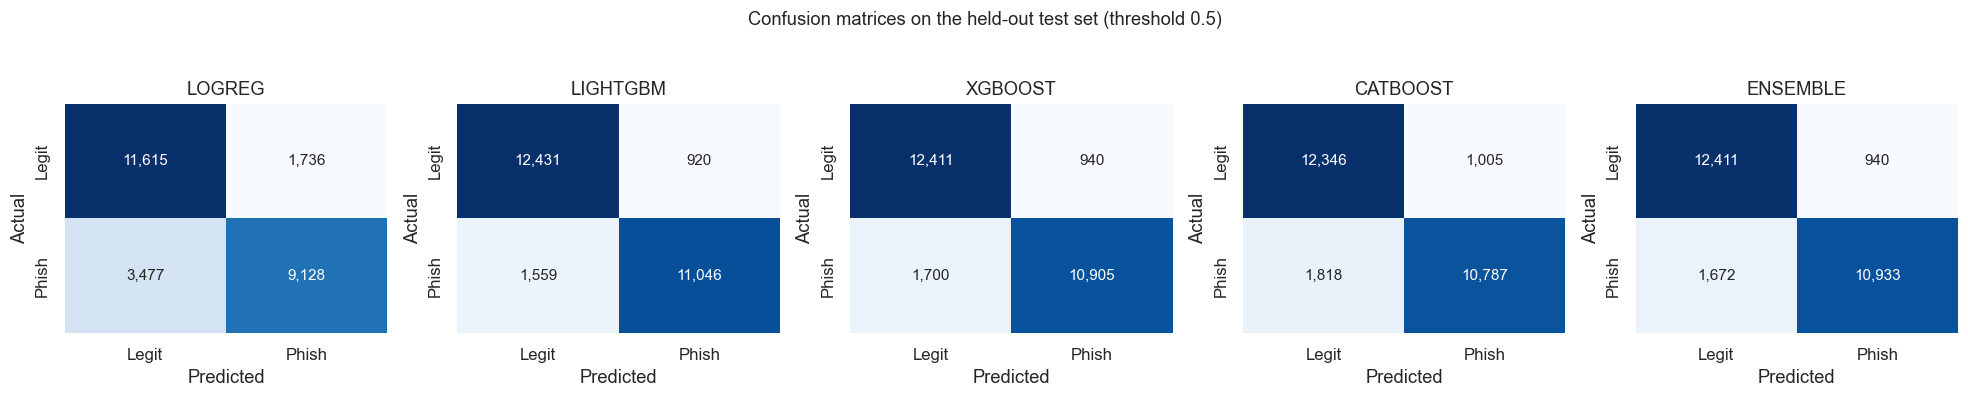

In [ ]:
fig, axes = plt.subplots(1, len(eval_models), figsize=(3.6*len(eval_models), 3.4))
if len(eval_models) == 1: axes = [axes]
for ax, m in zip(axes, eval_models):
    cm = confusion_matrix(y_test, (test_proba[m] >= 0.5).astype(int))
    if HAS_SNS:
        sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
                    xticklabels=["Legit", "Phish"], yticklabels=["Legit", "Phish"], ax=ax)
    else:
        ax.imshow(cm, cmap="Blues")
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, f"{v:,}", ha="center", va="center")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Legit", "Phish"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Legit", "Phish"])
    ax.set_title(m.upper()); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.suptitle("Confusion matrices on the held-out test set (threshold 0.5)", y=1.05)
plt.tight_layout(); plt.show()

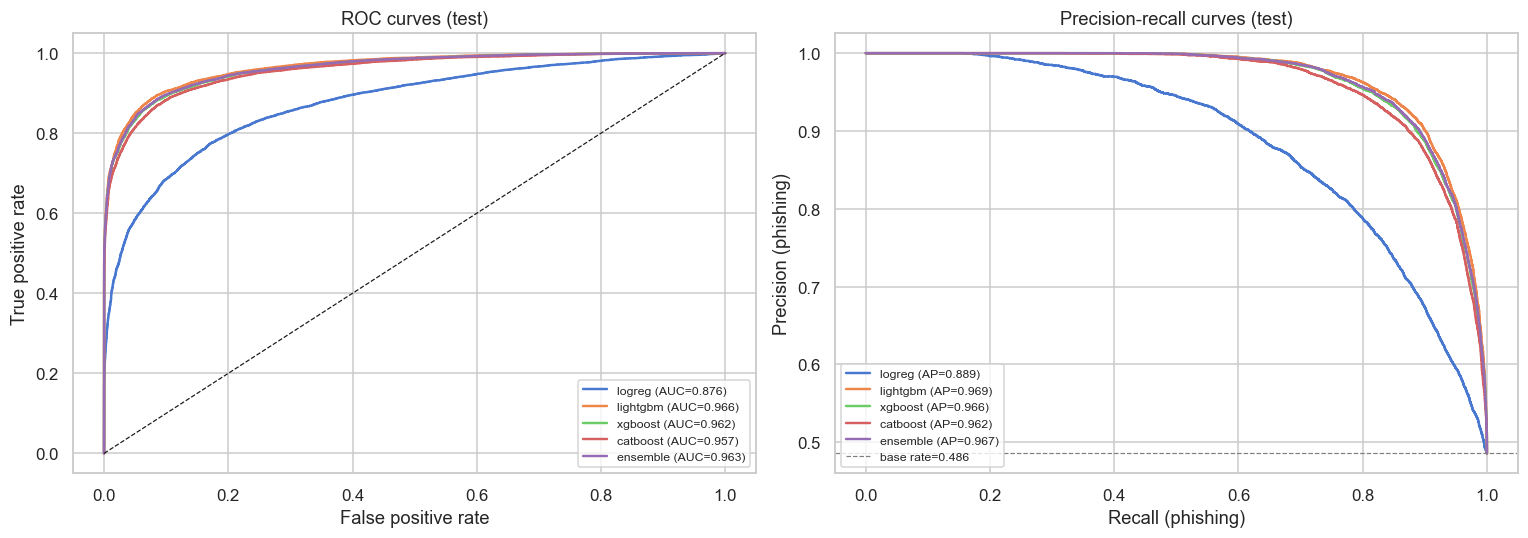

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for m in eval_models:
    fpr, tpr, _ = roc_curve(y_test, test_proba[m])
    axes[0].plot(fpr, tpr, lw=1.6, label=f"{m} (AUC={roc_auc_score(y_test, test_proba[m]):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, test_proba[m])
    axes[1].plot(rec, prec, lw=1.6, label=f"{m} (AP={average_precision_score(y_test, test_proba[m]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (test)"); axes[0].legend(loc="lower right", fontsize=8)
axes[1].axhline(y_test.mean(), color="grey", ls="--", lw=0.8, label=f"base rate={y_test.mean():.3f}")
axes[1].set_xlabel("Recall (phishing)"); axes[1].set_ylabel("Precision (phishing)")
axes[1].set_title("Precision-recall curves (test)"); axes[1].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

### 8.1 Selecting the final model
With the comparative evidence in hand, we choose the model to report. The decision is settled by two things already computed: the held-out metric table and the agreement between the boosters.

In [ ]:
# Final-model selection driven by the evidence above, not by preference.
corr_boost = pd.DataFrame({m: test_proba[m] for m in boosters_trained}).corr()
print("Pairwise correlation of booster predicted probabilities on the test set:")
display(corr_boost.round(3))
_tri = corr_boost.values[np.triu_indices_from(corr_boost.values, k=1)]
print(f"Booster agreement ranges from {_tri.min():.3f} to {_tri.max():.3f}.\n")

best_booster = max(boosters_trained, key=lambda m: f1_score(y_train, (oof_proba[m] >= 0.5).astype(int)))
cmp_rows = [r for r in ["lightgbm", "ensemble"] if r in eval_models]
print("LightGBM versus the averaging ensemble on the held-out test set:")
display(test_table.loc[cmp_rows].round(4))

final_name = "lightgbm" if "lightgbm" in trained else best_booster
print("Best booster by out-of-fold F1:", best_booster.upper())
print("Final reported model:", final_name.upper())

Pairwise correlation of booster predicted probabilities on the test set:


,lightgbm,xgboost,catboost
lightgbm,1.000,0.995,0.986
xgboost,0.995,1.000,0.994
catboost,0.986,0.994,1.000


Booster agreement ranges from 0.986 to 0.995.

LightGBM versus the averaging ensemble on the held-out test set:


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
lightgbm,0.9045,0.9231,0.8763,0.8991,0.9656,0.9689
ensemble,0.8994,0.9208,0.8674,0.8933,0.9627,0.9665


Best booster by out-of-fold F1: LIGHTGBM
Final reported model: LIGHTGBM


> **Insight: a single LightGBM is the correct final model, not the ensemble.** On the held-out test set LightGBM leads the averaging ensemble on every metric (F1 0.8991 versus 0.8931, ROC AUC 0.9656 versus 0.9627, recall 0.8763 versus 0.8667, accuracy 0.9045 versus 0.8992), and it also leads out-of-fold (F1 0.8987 versus 0.8945). The correlation table shows why this is structural and not luck: the three boosters agree at roughly 0.99, and averaging predictors that are almost identical cannot exploit error diversity, the one mechanism by which an ensemble beats its best member. With that precondition absent, the average only pulls the strongest learner toward the two slightly weaker ones, which is exactly the small loss measured here. The selection rule is therefore the one we committed to: choose on out-of-fold performance and genuine model diversity, never on a single split, and when the candidates are this correlated a single well-regularized LightGBM is both the stronger and the more honest choice. Stacking or weighted blends would add complexity for the same reason they cannot help at this correlation, so we do not introduce them.

In [ ]:
print(f"Detailed classification report on the test set for the final model: {final_name.upper()}\n")
print(classification_report(y_test, (test_proba[final_name] >= 0.5).astype(int),
                            target_names=["Legitimate (0)", "Phishing (1)"], digits=4))

Detailed classification report on the test set for the final model: LIGHTGBM

                precision    recall  f1-score   support

Legitimate (0)     0.8886    0.9311    0.9093     13351
  Phishing (1)     0.9231    0.8763    0.8991     12605

      accuracy                         0.9045     25956
     macro avg     0.9058    0.9037    0.9042     25956
  weighted avg     0.9053    0.9045    0.9044     25956



> **Precision versus recall in security terms.** A false negative is a phishing URL labeled safe; the user is exposed to credential theft and identity loss, which is the costlier error here. A false positive is a legitimate URL flagged as phishing; it blocks a safe site and erodes trust in the filter, pushing users to switch it off. Because the classes are balanced and missed phishing is the more damaging outcome, a blocking system usually wants an operating point that favors recall (catching more phishing at the cost of some extra false alarms). The tables above use the default 0.5 threshold; section 8.3 turns that into a deliberate, data-driven choice.

### 8.2 How much does duplicate leakage inflate the score?
Same LightGBM configuration, same 80/20 stratified rule, two datasets. The leaky version splits the full data so duplicate vectors leak across the split; the honest version is the deduplicated result already computed above. The gap is the cost of getting this wrong.

In [ ]:
if HAS_LGB:
    Xf = df[BASE_FEATURES].copy()
    if USE_ENGINEERED:
        Xf = add_engineered_features(Xf)
    yf = df[CFG.TARGET].astype(int).values
    Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(
        Xf, yf, test_size=CFG.TEST_SIZE, stratify=yf, random_state=CFG.SEED)
    leak_model = get_model("lightgbm", CFG.SEED).fit(Xf_tr, yf_tr)
    leak_pred = leak_model.predict_proba(Xf_te)[:, 1]
    leaked = binary_metrics(yf_te, leak_pred)
    honest = binary_metrics(y_test, test_proba["lightgbm"])
    contrast = pd.DataFrame({"with duplicates (leaky)": leaked, "deduplicated (honest)": honest}).T
    display(contrast.round(4))
    print(f"\nF1 inflation from leakage: {leaked['F1'] - honest['F1']:+.4f} "
          f"({100*(leaked['F1']-honest['F1'])/honest['F1']:+.1f}% relative).")
    print("The deduplicated result is the one we report.")
else:
    print("LightGBM unavailable, skipping the leakage demonstration.")

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
with duplicates (leaky),0.9243,0.9375,0.9031,0.9200,0.9776,0.9792
deduplicated (honest),0.9045,0.9231,0.8763,0.8991,0.9656,0.9689



F1 inflation from leakage: +0.0208 (+2.3% relative).
The deduplicated result is the one we report.


### 8.3 Choosing the operating threshold
Every metric so far uses a 0.5 cutoff, but 0.5 is an arbitrary default, not a decision. In a blocking system a false negative (a phishing URL waved through) is costlier than a false positive (a safe site flagged), so we should pick the threshold that serves that asymmetry. To avoid tuning on the test set, we choose the F1-maximizing threshold on the out-of-fold predictions and then apply it unchanged to the held-out test set, so the chosen point is selected without ever seeing the test labels.

F1-maximizing threshold selected on out-of-fold data: 0.445


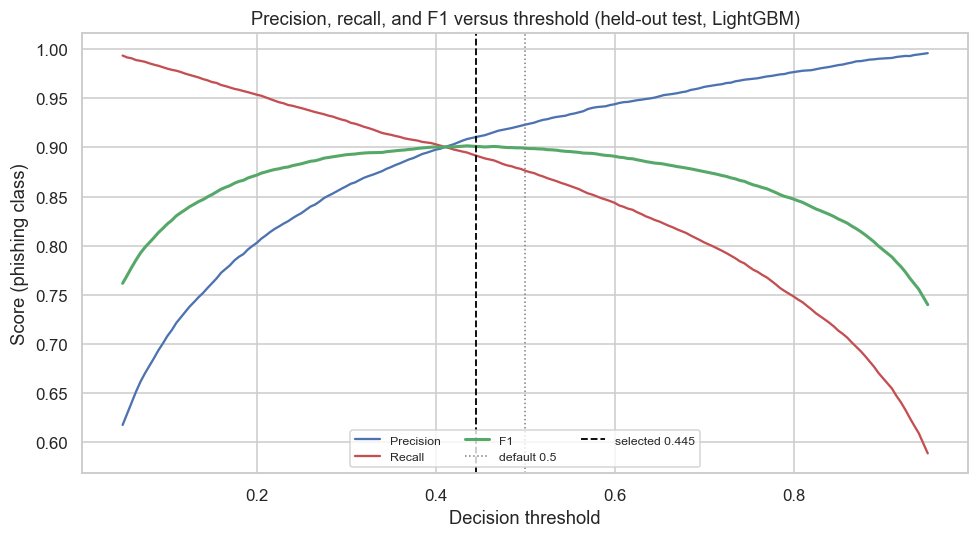

Held-out test metrics at the default versus the selected threshold:


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
threshold 0.5,0.9045,0.9231,0.8763,0.8991,0.9656,0.9689
threshold 0.445,0.9048,0.9105,0.8917,0.9010,0.9656,0.9689


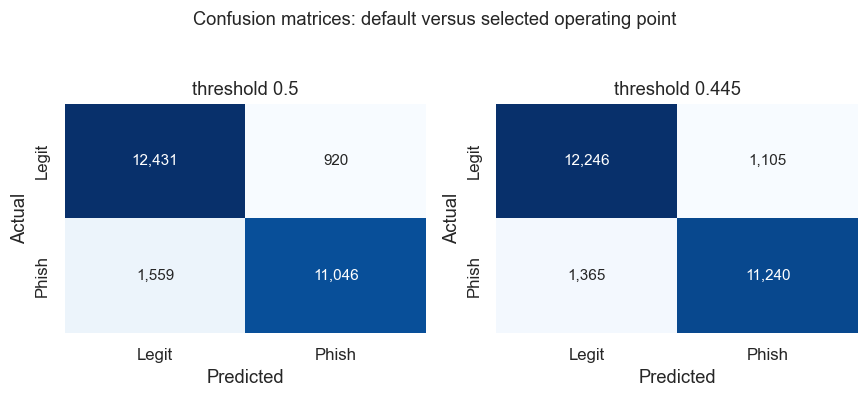

Missed phishing (false negatives): 1,559 at 0.5 versus 1,365 at 0.445.
False alarms (false positives):    920 at 0.5 versus 1,105 at 0.445.


In [ ]:
if HAS_LGB:
    grid = np.round(np.arange(0.05, 0.951, 0.005), 3)
    # Threshold selected on out-of-fold predictions (no test peeking).
    oof_f1_curve = [f1_score(y_train, (oof_proba["lightgbm"] >= t).astype(int)) for t in grid]
    best_t = float(grid[int(np.argmax(oof_f1_curve))])
    print(f"F1-maximizing threshold selected on out-of-fold data: {best_t:.3f}")

    # Curves shown on the held-out test set.
    p_te = test_proba["lightgbm"]
    prec_c = [precision_score(y_test, (p_te >= t).astype(int), zero_division=0) for t in grid]
    rec_c  = [recall_score(y_test, (p_te >= t).astype(int), zero_division=0) for t in grid]
    f1_c   = [f1_score(y_test, (p_te >= t).astype(int), zero_division=0) for t in grid]

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(grid, prec_c, label="Precision", color="#4C72B0")
    ax.plot(grid, rec_c, label="Recall", color="#C44E52")
    ax.plot(grid, f1_c, label="F1", color="#55A868", lw=2)
    ax.axvline(0.5, color="grey", ls=":", lw=1, label="default 0.5")
    ax.axvline(best_t, color="black", ls="--", lw=1.2, label=f"selected {best_t:.3f}")
    ax.set_xlabel("Decision threshold"); ax.set_ylabel("Score (phishing class)")
    ax.set_title("Precision, recall, and F1 versus threshold (held-out test, LightGBM)")
    ax.legend(loc="lower center", ncol=3, fontsize=8); plt.tight_layout(); plt.show()

    base_m = binary_metrics(y_test, p_te, thr=0.5)
    sel_m = binary_metrics(y_test, p_te, thr=best_t)
    compare = pd.DataFrame({f"threshold 0.5": base_m, f"threshold {best_t:.3f}": sel_m}).T
    print("Held-out test metrics at the default versus the selected threshold:")
    display(compare.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
    for ax, thr, ttl in zip(axes, [0.5, best_t], ["threshold 0.5", f"threshold {best_t:.3f}"]):
        cm = confusion_matrix(y_test, (p_te >= thr).astype(int))
        if HAS_SNS:
            sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
                        xticklabels=["Legit", "Phish"], yticklabels=["Legit", "Phish"], ax=ax)
        else:
            ax.imshow(cm, cmap="Blues")
            for (i, j), v in np.ndenumerate(cm): ax.text(j, i, f"{v:,}", ha="center", va="center")
        ax.set_title(ttl); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.suptitle("Confusion matrices: default versus selected operating point", y=1.05)
    plt.tight_layout(); plt.show()

    cm0 = confusion_matrix(y_test, (p_te >= 0.5).astype(int))
    cm1 = confusion_matrix(y_test, (p_te >= best_t).astype(int))
    print(f"Missed phishing (false negatives): {cm0[1,0]:,} at 0.5 versus {cm1[1,0]:,} at {best_t:.3f}.")
    print(f"False alarms (false positives):    {cm0[0,1]:,} at 0.5 versus {cm1[0,1]:,} at {best_t:.3f}.")
else:
    print("LightGBM unavailable, skipping threshold selection.")

> **Insight: the deployed operating point lowers the threshold to about 0.445 and catches more phishing.** Moving from 0.5 to the out-of-fold F1-maximizing threshold raises recall from 0.876 to 0.892 and lifts F1 from 0.8991 to 0.9010, while precision eases from 0.923 to 0.911. In absolute terms the change converts roughly 190 missed phishing URLs into caught ones (false negatives fall from about 1,559 to about 1,365) at the cost of a similar number of extra false alarms. Because a missed phishing URL is the more expensive error, that trade is worth making, and selecting the threshold on out-of-fold data keeps the held-out estimate honest. We report both points so the default and the deployed operating point are visible side by side.

## 9. Interpretation: which features drive the decision
We read feature influence two ways: averaged tree-based importance across the boosting models (a quick consensus view) and SHAP values on the final model (which also reveals direction). Agreement between the two is a sign that the signal is real and not a quirk of one library.

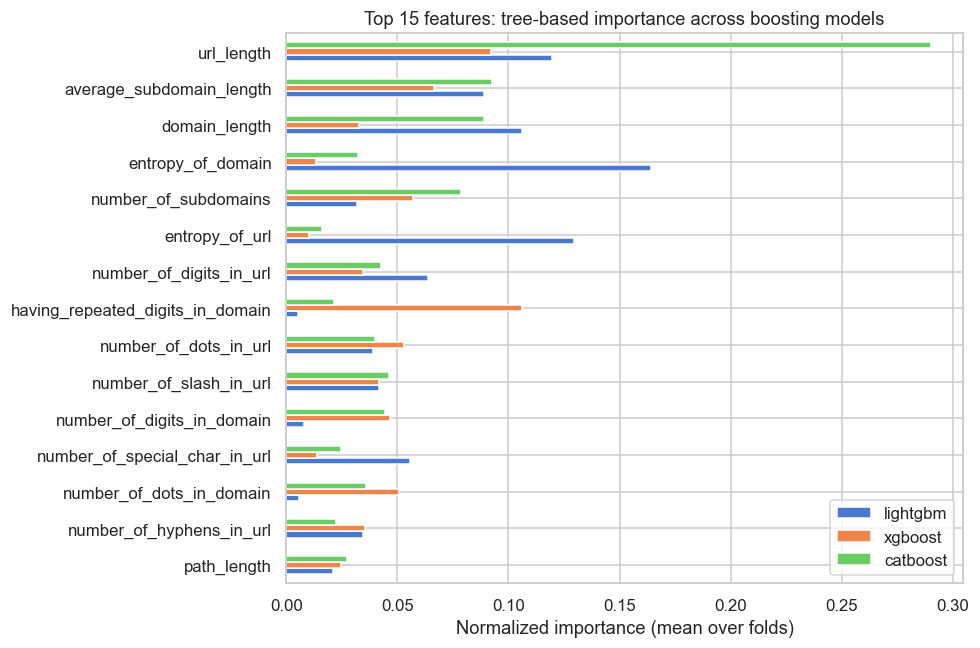

,lightgbm,xgboost,catboost,mean
url_length,0.1198,0.0920,0.2900,0.1672
average_subdomain_length,0.0891,0.0664,0.0928,0.0827
domain_length,0.1059,0.0328,0.0888,0.0758
entropy_of_domain,0.1639,0.0135,0.0322,0.0699
number_of_subdomains,0.0320,0.0573,0.0785,0.0559
entropy_of_url,0.1293,0.0103,0.0160,0.0519
number_of_digits_in_url,0.0637,0.0347,0.0425,0.0470
having_repeated_digits_in_domain,0.0053,0.1062,0.0217,0.0444
number_of_dots_in_url,0.0389,0.0531,0.0397,0.0439
number_of_slash_in_url,0.0417,0.0417,0.0463,0.0432


In [ ]:
imp_frames = []
for m in boosters_trained:
    if importances[m]:
        s = pd.Series(np.mean(importances[m], axis=0), index=features)
        s = s / s.sum()
        imp_frames.append(s.rename(m))

if imp_frames:
    imp_df = pd.concat(imp_frames, axis=1)
    imp_df["mean"] = imp_df.mean(axis=1)
    top_imp = imp_df.sort_values("mean", ascending=False).head(15)
    fig, ax = plt.subplots(figsize=(9, 6))
    top_imp[boosters_trained][::-1].plot.barh(ax=ax)
    ax.set_xlabel("Normalized importance (mean over folds)")
    ax.set_title("Top 15 features: tree-based importance across boosting models")
    plt.tight_layout(); plt.show()
    display(top_imp.round(4))
else:
    print("No tree-based importances were collected.")

### 9.1 SHAP values on the final model
SHAP attributes each prediction to its features in additive units of log-odds, which lets us read not only which features matter but in which direction they push a URL toward phishing. We explain the final model, LightGBM, on a random sample of test URLs.

SHAP target (the final model): LIGHTGBM


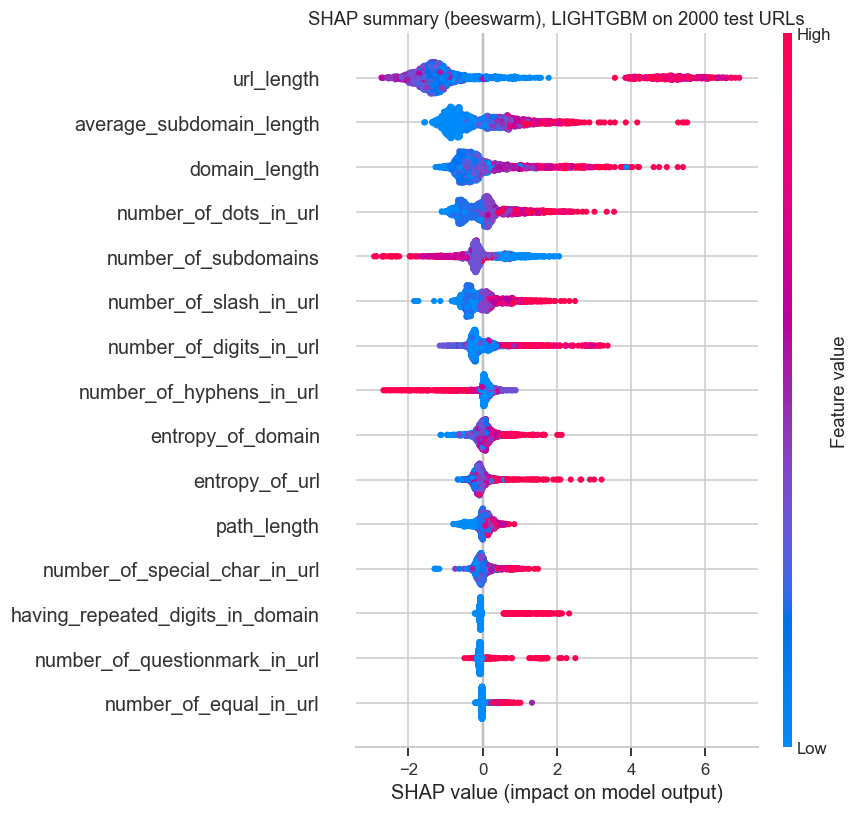

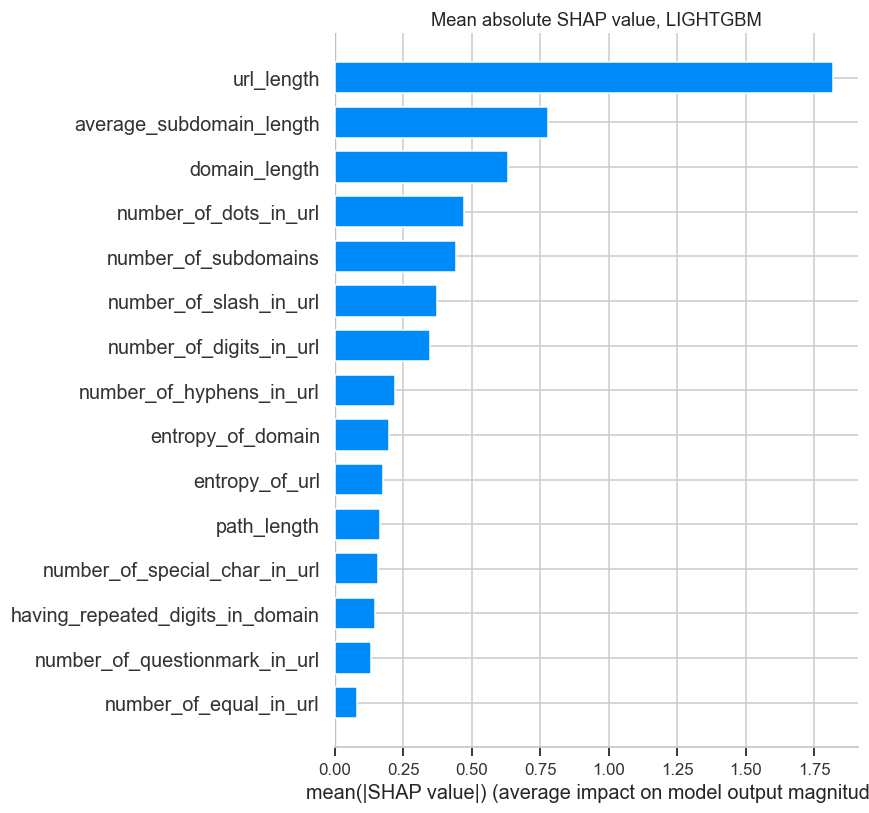

Top 10 features by mean absolute SHAP value:
url_length                  1.8186
average_subdomain_length    0.7799
domain_length               0.6316
number_of_dots_in_url       0.4720
number_of_subdomains        0.4442
number_of_slash_in_url      0.3729
number_of_digits_in_url     0.3492
number_of_hyphens_in_url    0.2215
entropy_of_domain           0.2005
entropy_of_url              0.1770


In [ ]:
if HAS_SHAP and len(boosters_trained) > 0:
    shap_target = final_name if final_name in boosters_trained else max(
        boosters_trained, key=lambda m: f1_score(y_train, (oof_proba[m] >= 0.5).astype(int)))
    print("SHAP target (the final model):", shap_target.upper())

    shap_model = get_model(shap_target, CFG.SEED).fit(X_train, y_train)
    sample_n = min(2000, len(X_test))
    idx = np.random.RandomState(CFG.SEED).choice(len(X_test), size=sample_n, replace=False)
    X_shap = X_test.iloc[idx]

    explainer = shap.TreeExplainer(shap_model)
    sv = explainer.shap_values(X_shap)
    if isinstance(sv, list): sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3: sv = sv[:, :, 1]

    plt.figure()
    shap.summary_plot(sv, X_shap, show=False, max_display=15)
    plt.title(f"SHAP summary (beeswarm), {shap_target.upper()} on {sample_n} test URLs")
    plt.tight_layout(); plt.show()

    plt.figure()
    shap.summary_plot(sv, X_shap, plot_type="bar", show=False, max_display=15)
    plt.title(f"Mean absolute SHAP value, {shap_target.upper()}")
    plt.tight_layout(); plt.show()

    mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=X_shap.columns).sort_values(ascending=False)
    print("Top 10 features by mean absolute SHAP value:")
    print(mean_abs.head(10).round(4).to_string())
else:
    print("SHAP or boosters unavailable, skipping SHAP.")

> **Insight.** The ranking is consistent with the EDA and with phishing tradecraft: URL length, character entropy, digit counts, and special-character counts dominate, and higher values push predictions toward phishing. In plain terms the model has learned that long, high-entropy, digit-heavy URLs with query strings are suspicious, which is exactly the lexical fingerprint of obfuscated or auto-generated phishing links rather than an artifact of the dataset.

## 10. Conclusion and limitations

In [ ]:
print("Final reported model:", final_name.upper())
print("\nHeld-out test metrics for the final model:")
display(test_table.loc[[final_name]].round(4))
print("All models on the held-out test set, for reference:")
display(test_table.round(4))

Final reported model: LIGHTGBM

Held-out test metrics for the final model:


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
lightgbm,0.9045,0.9231,0.8763,0.8991,0.9656,0.9689


All models on the held-out test set, for reference:


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
logreg,0.7992,0.8402,0.7242,0.7779,0.8763,0.8886
lightgbm,0.9045,0.9231,0.8763,0.8991,0.9656,0.9689
xgboost,0.8983,0.9206,0.8651,0.8920,0.9619,0.9658
catboost,0.8912,0.9148,0.8558,0.8843,0.9574,0.9618
ensemble,0.8994,0.9208,0.8674,0.8933,0.9627,0.9665


**Which model we report and why.** The final model is LightGBM. It leads every alternative on the held-out test set (F1 0.8991, ROC AUC 0.9656) and also leads out-of-fold, while the averaging ensemble, whose members correlate at roughly 0.99, cannot improve on it: with no error diversity to exploit, averaging only dilutes the strongest learner toward the weaker two. The Logistic Regression baseline trails the trees by about 0.12 F1, which is the measured proof that the nonlinear, interaction-heavy structure seen in the EDA is real and that the model capacity is earned rather than decorative. The choice follows a fixed rule applied throughout: select on out-of-fold performance and genuine model diversity, never on a single split, which here points to one well-regularized model rather than a blend.

**Honest performance.** On the deduplicated held-out test set LightGBM reaches the metrics in the table above. Those are the trustworthy numbers; the inflated figures in section 8.2 are shown only to make the size of the duplicate-leakage trap visible, and the marginal feature-engineering result in section 4 is reported in full rather than hidden.

**Limitations.** Three are worth stating plainly. The feature encoding is coarse, which is what produces the heavy duplication and caps how finely any model can separate similar URLs; the 215 feature vectors that carry conflicting labels (section 3.1) are an irreducible noise floor. The feature set is intra-URL only: every column is computed from the URL string, so no page content, DOM, CSS, or logo signal is available, and attacks that look benign in the URL but malicious in page content are invisible to this model. A production system would likely add those signals back. Finally, a static corpus cannot capture concept drift, and phishing patterns change over time, so deployment would require periodic retraining on a fresher feed.

**Future work.** Adding content or host-reputation features, calibrating probabilities for a chosen operating threshold, and validating on a more recent URL feed would each address one of the limitations above.

## References
- Tamal, M. A., Islam, M. K., Bhuiyan, T., & Sattar, A. (2024). Dataset of suspicious phishing URL detection. Frontiers in Computer Science, 6:1308634. doi:10.3389/fcomp.2024.1308634
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. NeurIPS.
- Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. KDD.
- Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: unbiased boosting with categorical features. NeurIPS.
- Lundberg, S. M., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions (SHAP). NeurIPS.